### 06 — Pathway enrichment and the Bola3 mechanistic hypothesis

**You have a strong prior, and you should use it.** BOLA3 is a late-acting
mitochondrial Fe–S cluster assembly factor. With NFU1 and GLRX5 it inserts
[4Fe-4S] clusters into a defined set of client proteins, most prominently
lipoyl synthase (LIAS) and succinate dehydrogenase (complex II). Its loss
causes multiple mitochondrial dysfunctions syndrome type 2 in humans.

So the mechanism predicts a specific ordered chain:

```
  Bola3 loss
    -> failed [4Fe-4S] insertion into LIAS and SDH
    -> loss of protein lipoylation (PDH, OGDH, GCS)
    -> TCA flux and complex I/II/III activity fall
    -> ATP production drops, ROS rise
    -> integrated stress response (Atf4, Ddit3, Fgf21, Gdf15) activates
    -> in beta cells specifically: ATP/ADP-coupled insulin secretion fails,
       and beta cells lose the metabolically-enforced mature identity
       (Ucn3, Mafa down; Aldh1a3 and the "disallowed" genes up)
```

Testing that chain explicitly is a stronger piece of science than reporting
whichever Hallmark set happens to clear FDR. `resources/bola3_gene_sets.py`
encodes each link as a gene set, together with a **direction predicted in
advance** in `DIRECTIONAL_HYPOTHESES`. This notebook tests those predictions
first, then runs the unbiased analysis as a check on whether the prior missed
something.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
sys.path.insert(0, str(Path.cwd().parent / "resources"))

import warnings

import decoupler as dc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

import config as cfg
from bola3_gene_sets import (DIRECTIONAL_HYPOTHESES, GENE_SETS, as_decoupler_net,
                             filter_sets, write_gmt)

warnings.simplefilter("ignore", category=FutureWarning)
sc.settings.set_figure_params(dpi=90, dpi_save=300, frameon=False)

adata = sc.read_h5ad(cfg.H5AD["final"])
de = pd.read_csv(cfg.TABLE_DIR / "05_pseudobulk_de_all.csv")
PALETTE = {"WT": "#4C72B0", "KO": "#C44E52"}

sets = filter_sets(GENE_SETS, adata.var_names, min_genes=5)
net = as_decoupler_net(sets)
write_gmt(sets, cfg.TABLE_DIR / "bola3_gene_sets.gmt")
print(f"\n{len(sets)} gene sets retained")

Genes not found in the object (usually fine -- filtered out at QC):
  FeS_assembly_core                missing   3: Ciao2a, Ciao2b, Ciao3
  OXPHOS_complexI                  missing   1: Ndufb1
  OXPHOS_all                       missing  16: Atp5f1a, Atp5f1b, Atp5f1c, Atp5f1d, Atp5f1e, Atp5if1, Atp5mc1, Atp5mc2 ...
  Integrated_stress_response       missing   2: Gars1, Sars1
  Mitochondrial_UPR                missing   1: Phb1
  Ferroptosis                      missing   1: Mboat5

21 gene sets retained


/Users/sashe/Projects/Bola3/Bola3_scRNAseq/Bola3_scRNAseq_Analysis/resources/bola3_gene_sets.py:306: UserWarning: gene set 'OXPHOS_complexII' dropped: only 4/4 genes found in the object (min_genes=5)
  warnings.warn(
/Users/sashe/Projects/Bola3/Bola3_scRNAseq/Bola3_scRNAseq_Analysis/resources/bola3_gene_sets.py:306: UserWarning: gene set 'OXPHOS_complexV' dropped: only 0/15 genes found in the object (min_genes=5)
  warnings.warn(


### 6.1 The pre-registered test

GSEA on each cell type's DE ranking, restricted to the curated sets. Genes are
ranked by the DESeq2 Wald statistic, which incorporates both effect size and
its uncertainty — a better ranking than log2FC alone, which puts noisy
low-count genes at the extremes.

In [2]:
rows = []
for ct, sub in de.groupby("cell_type"):
    ranks = (sub.dropna(subset=["stat"])
             .set_index("gene")[["stat"]].T)
    ranks.index = [ct]
    try:
        # decoupler 2.x returns a 2-tuple: (normalised enrichment score, p-value).
        # In decoupler 1.x this was `dc.run_gsea` and wrote into an AnnData --
        # another call that has changed since the HNOCA notebooks were written.
        nes, pval = dc.mt.gsea(data=ranks, net=net, tmin=5)
        rows.append(pd.DataFrame({
            "cell_type": ct,
            "gene_set": nes.columns,
            "norm_score": nes.iloc[0].values,
            "pvalue": pval.iloc[0].values,
        }))
    except Exception as e:
        print(f"  {ct}: GSEA failed ({e})")

gsea = pd.concat(rows, ignore_index=True)
from statsmodels.stats.multitest import multipletests

gsea["FDR"] = np.nan
for ct, idx in gsea.groupby("cell_type").groups.items():
    gsea.loc[idx, "FDR"] = multipletests(gsea.loc[idx, "pvalue"], method="fdr_bh")[1]

gsea["predicted"] = gsea["gene_set"].map(DIRECTIONAL_HYPOTHESES)
gsea["observed"] = np.where(gsea["norm_score"] > 0, "up", "down")
gsea["prediction_met"] = (
    (gsea["predicted"] == gsea["observed"]) & (gsea["FDR"] < 0.05)
)
gsea.to_csv(cfg.TABLE_DIR / "06_gsea_bola3_sets.csv", index=False)

3 / 14 directional predictions confirmed in beta cells at FDR < 0.05


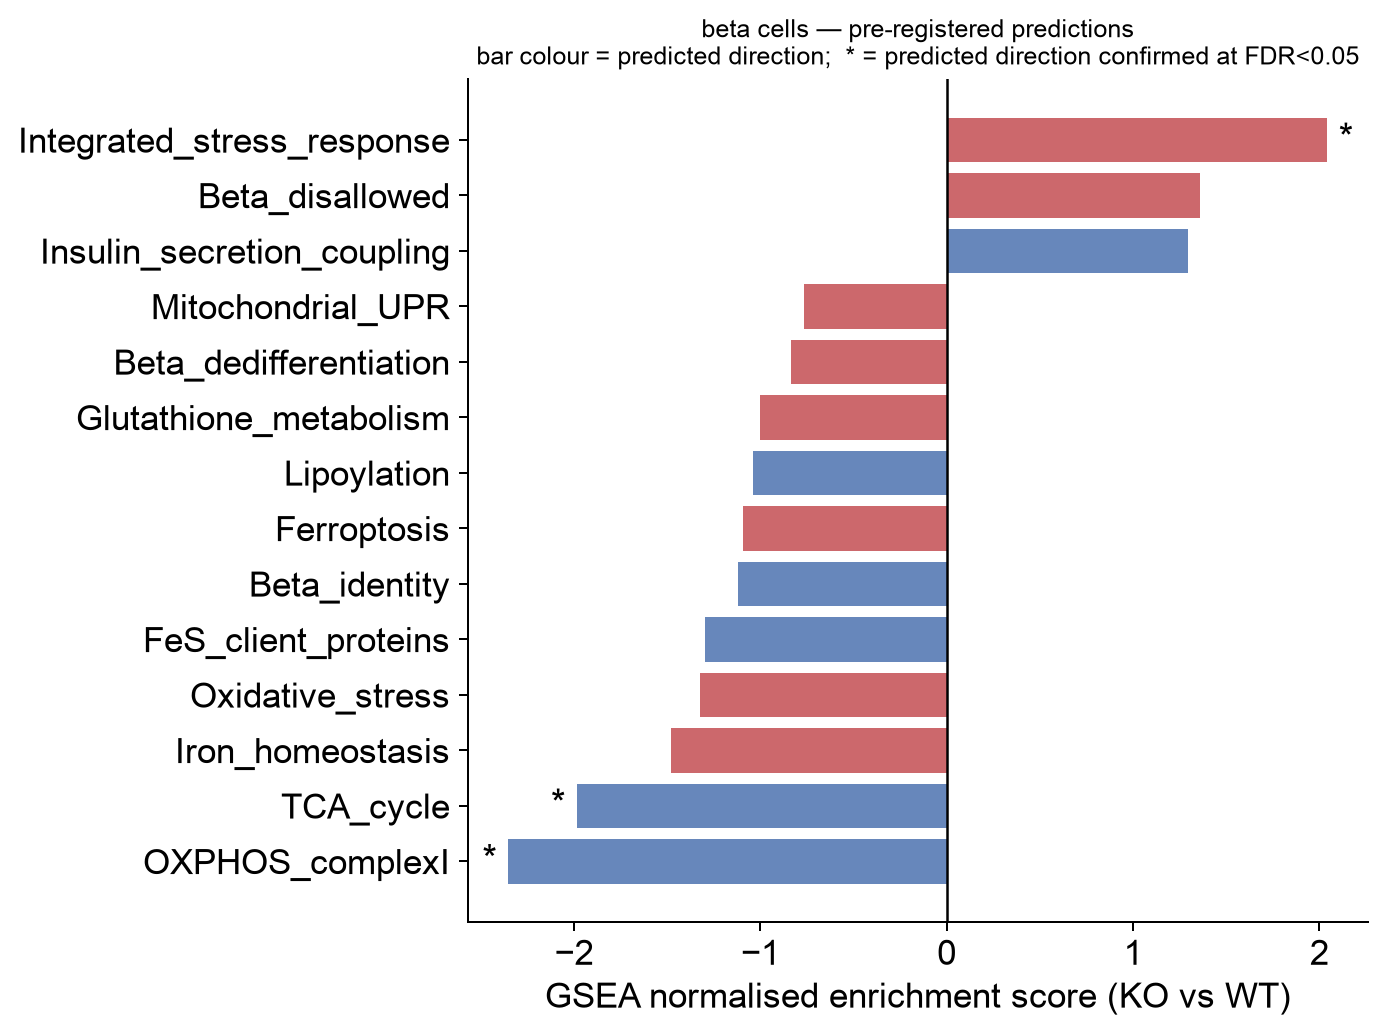

In [4]:
FOCUS = "beta" if "beta" in gsea.cell_type.unique() else gsea.cell_type.iloc[0]
focus = gsea[gsea.cell_type == FOCUS].dropna(subset=["predicted"]).copy()
focus = focus.sort_values("norm_score")

fig, ax = plt.subplots(figsize=(8, 6))
colours = ["#C44E52" if p == "up" else "#4C72B0" for p in focus["predicted"]]
bars = ax.barh(focus["gene_set"], focus["norm_score"], color=colours, alpha=0.85)
for bar, met, fdr in zip(bars, focus["prediction_met"], focus["FDR"]):
    if met:
        ax.text(bar.get_width() + np.sign(bar.get_width()) * 0.06,
                bar.get_y() + bar.get_height() / 2, "*", va="center",
                ha="left" if bar.get_width() > 0 else "right", fontsize=15)
ax.axvline(0, c="k", lw=1)
ax.set_xlabel("GSEA normalised enrichment score (KO vs WT)")
ax.set_title(f"{FOCUS} cells — pre-registered predictions\n"
             "bar colour = predicted direction;  * = predicted direction confirmed at FDR<0.05",
             fontsize=10)
ax.grid(False)
sns.despine(); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / f"06_directional_predictions_{FOCUS}.png",
            dpi=300, bbox_inches="tight")

n_met = focus["prediction_met"].sum()
print(f"{n_met} / {focus['predicted'].notna().sum()} directional predictions "
      f"confirmed in {FOCUS} cells at FDR < 0.05")

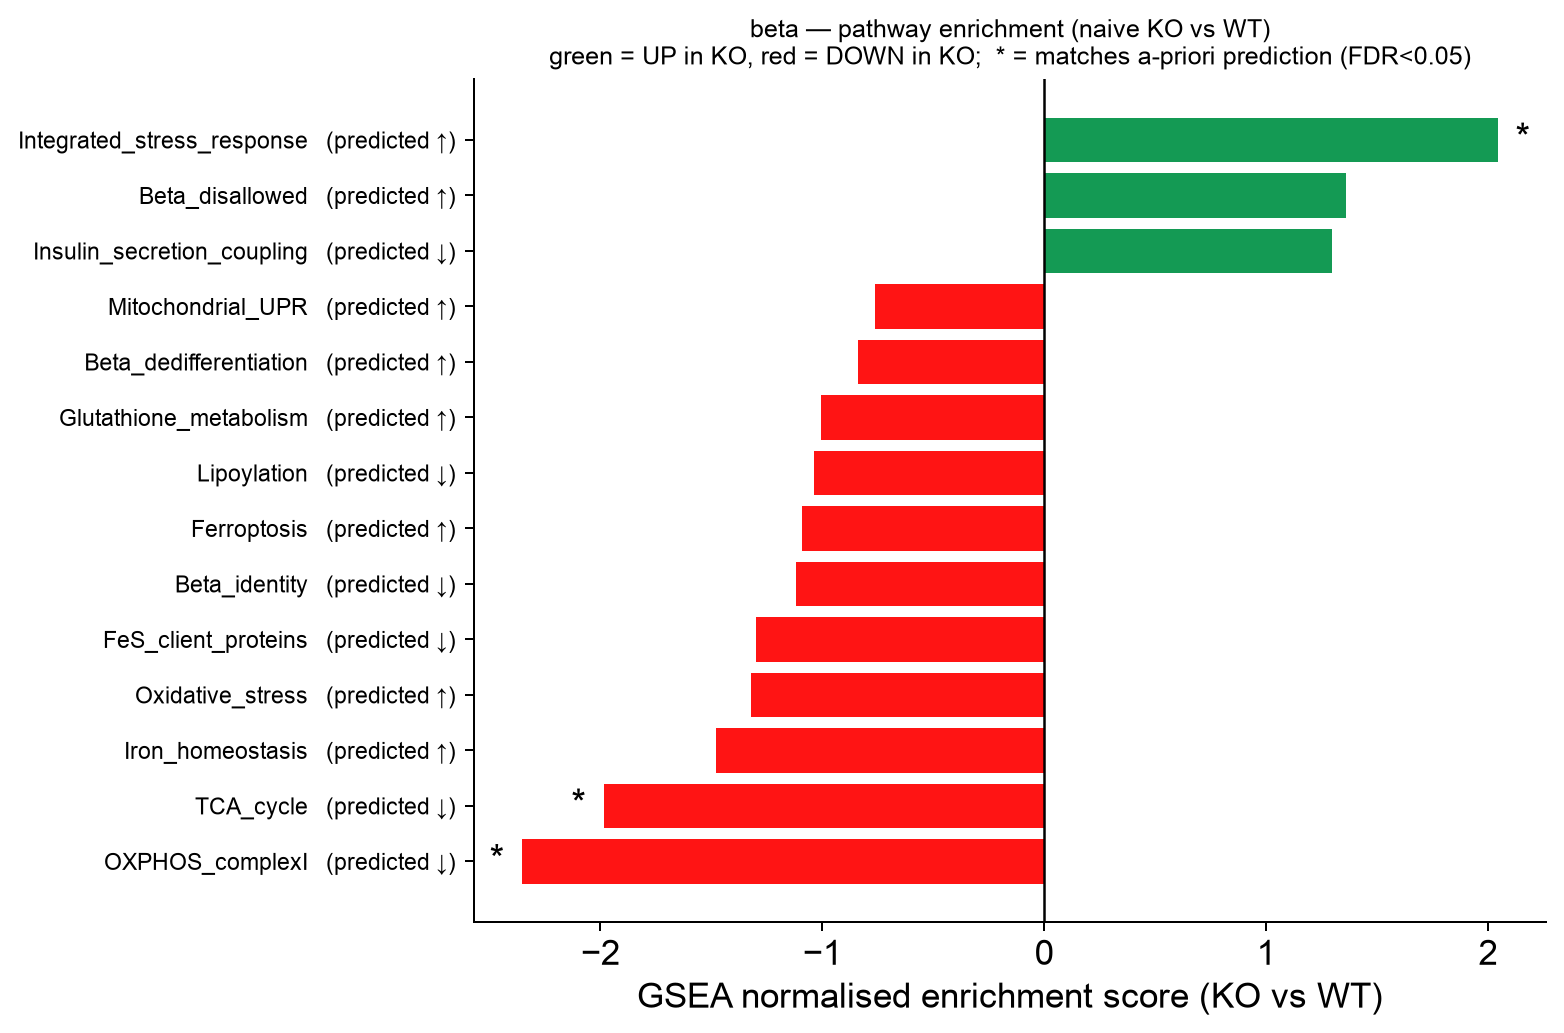

In [7]:
import numpy as np, matplotlib.pyplot as plt, seaborn as sns

focus = gsea[gsea.cell_type == FOCUS].dropna(subset=["predicted"]).copy().sort_values("norm_score")
UP, DOWN = "#009245", "#ff0000"
colours = [UP if v > 0 else DOWN for v in focus["norm_score"]]         # colour = OBSERVED direction
arr = {"up": "↑", "down": "↓"}
ylabs = [f"{s}   (predicted {arr.get(p,'?')})" for s, p in zip(focus["gene_set"], focus["predicted"])]

fig, ax = plt.subplots(figsize=(8.8, 6))
ax.barh(range(len(focus)), focus["norm_score"], color=colours, alpha=0.92)
ax.set_yticks(range(len(focus))); ax.set_yticklabels(ylabs, fontsize=9)
for i, (met, w) in enumerate(zip(focus["prediction_met"], focus["norm_score"])):
    if met:
        ax.text(w + np.sign(w)*0.08, i, "*", va="center", ha="left" if w > 0 else "right", fontsize=15)
ax.axvline(0, c="k", lw=1)
ax.set_xlabel("GSEA normalised enrichment score (KO vs WT)")
ax.set_title(f"{FOCUS} — pathway enrichment (naive KO vs WT)\n"
             "green = UP in KO, red = DOWN in KO;  * = matches a-priori prediction (FDR<0.05)", fontsize=10)
ax.grid(False)
sns.despine(); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / f"06_directional_predictions_{FOCUS}.png", dpi=300, bbox_inches="tight")
plt.show()

### Scorecard

Read this as a mechanism test rather than a gene list. If lipoylation and
complex II are down while the ISR is up, you have reproduced the known BOLA3
biochemistry transcriptionally, and the beta-cell rows then tell you what that
lesion does to islet function. If lipoylation and complex II are *unchanged*,
your KO may be hypomorphic, compensated, or too early to have manifested — all
real possibilities, and all worth knowing before you write a discussion around
a downstream effect.

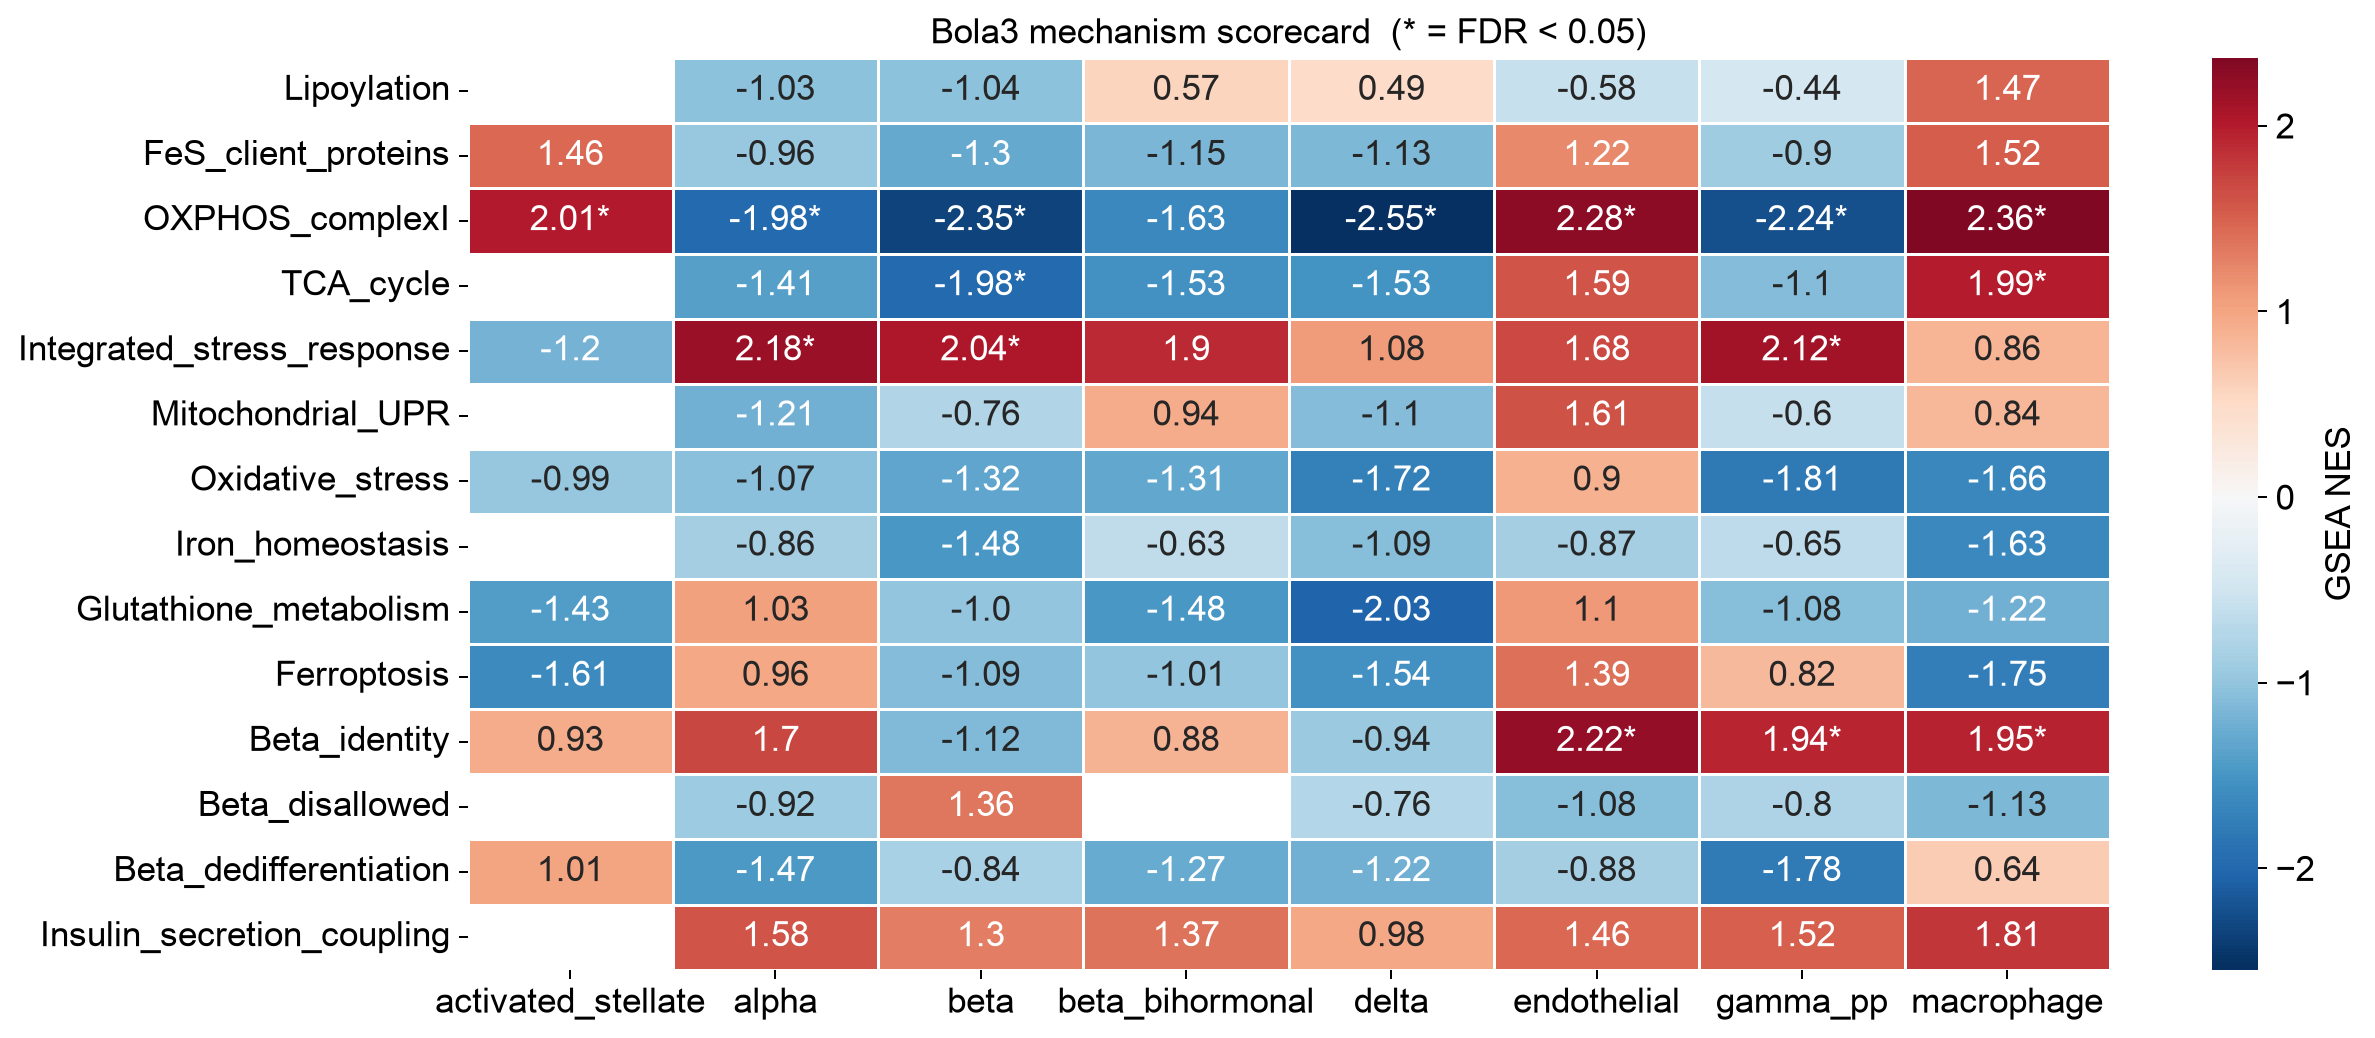

In [9]:
score_card = (gsea.dropna(subset=["predicted"])
              .pivot_table(index="gene_set", columns="cell_type",
                           values="norm_score"))
sig_mask = (gsea.dropna(subset=["predicted"])
            .pivot_table(index="gene_set", columns="cell_type", values="FDR")) < 0.05
annot = score_card.round(2).astype(str)
annot = annot.where(~sig_mask, annot + "*")

order = [k for k in DIRECTIONAL_HYPOTHESES if k in score_card.index]
fig, ax = plt.subplots(figsize=(1.3 * score_card.shape[1] + 4, 6))
sns.heatmap(score_card.loc[order], cmap="RdBu_r", center=0, annot=annot.loc[order],
            fmt="", ax=ax, cbar_kws={"label": "GSEA NES"}, linewidths=0.5)
ax.set_title("Bola3 mechanism scorecard  (* = FDR < 0.05)")
ax.set_xlabel(""); ax.set_ylabel("")
ax.grid(False)
fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "06_mechanism_scorecard.png", dpi=300, bbox_inches="tight")

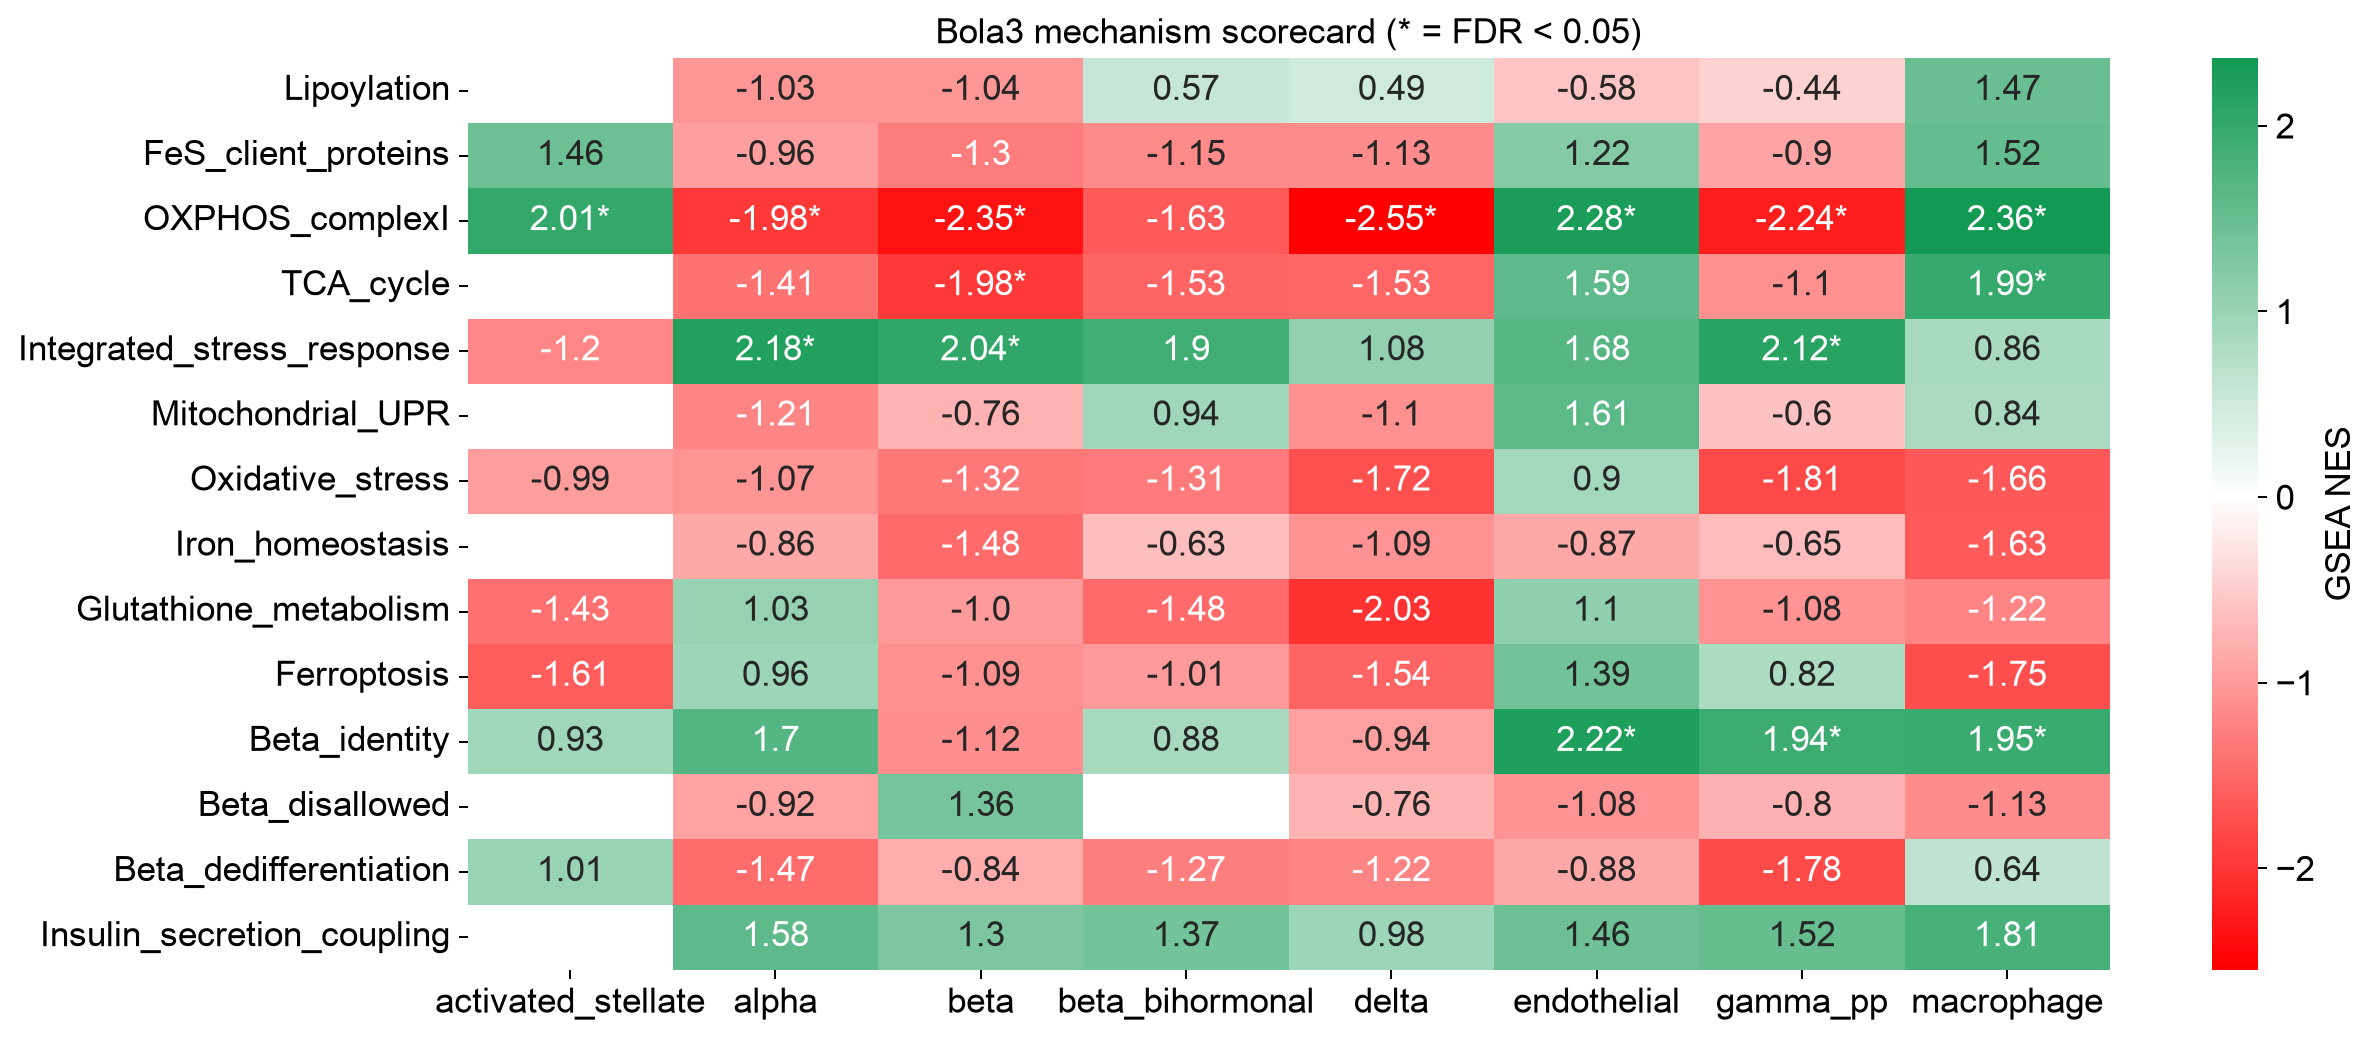

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

score_card = (gsea.dropna(subset=["predicted"]) 
              .pivot_table(index="gene_set", columns="cell_type", values="norm_score")) 

sig_mask = (gsea.dropna(subset=["predicted"]) 
            .pivot_table(index="gene_set", columns="cell_type", values="FDR")) < 0.05 

annot = score_card.round(2).astype(str) 
annot = annot.where(~sig_mask, annot + "*") 
order = [k for k in DIRECTIONAL_HYPOTHESES if k in score_card.index] 

# Custom colormap blending: Downregulated (Red) -> Neutral (White) -> Upregulated (Green)
custom_cmap = LinearSegmentedColormap.from_list("RedGreen", ["#ff0000", "#ffffff", "#009245"])

fig, ax = plt.subplots(figsize=(1.3 * score_card.shape[1] + 4, 6)) 

# Changed linewidths to 0 to remove the borders between cells
sns.heatmap(score_card.loc[order], cmap=custom_cmap, center=0, annot=annot.loc[order], fmt="", ax=ax, cbar_kws={"label": "GSEA NES"}, linewidths=0) 

ax.set_title("Bola3 mechanism scorecard (* = FDR < 0.05)") 
ax.set_xlabel(""); ax.set_ylabel("") 
ax.grid(False) 

fig.tight_layout() 
fig.savefig(cfg.FIG_DIR / "06_mechanism_scorecard.png", dpi=300, bbox_inches="tight")

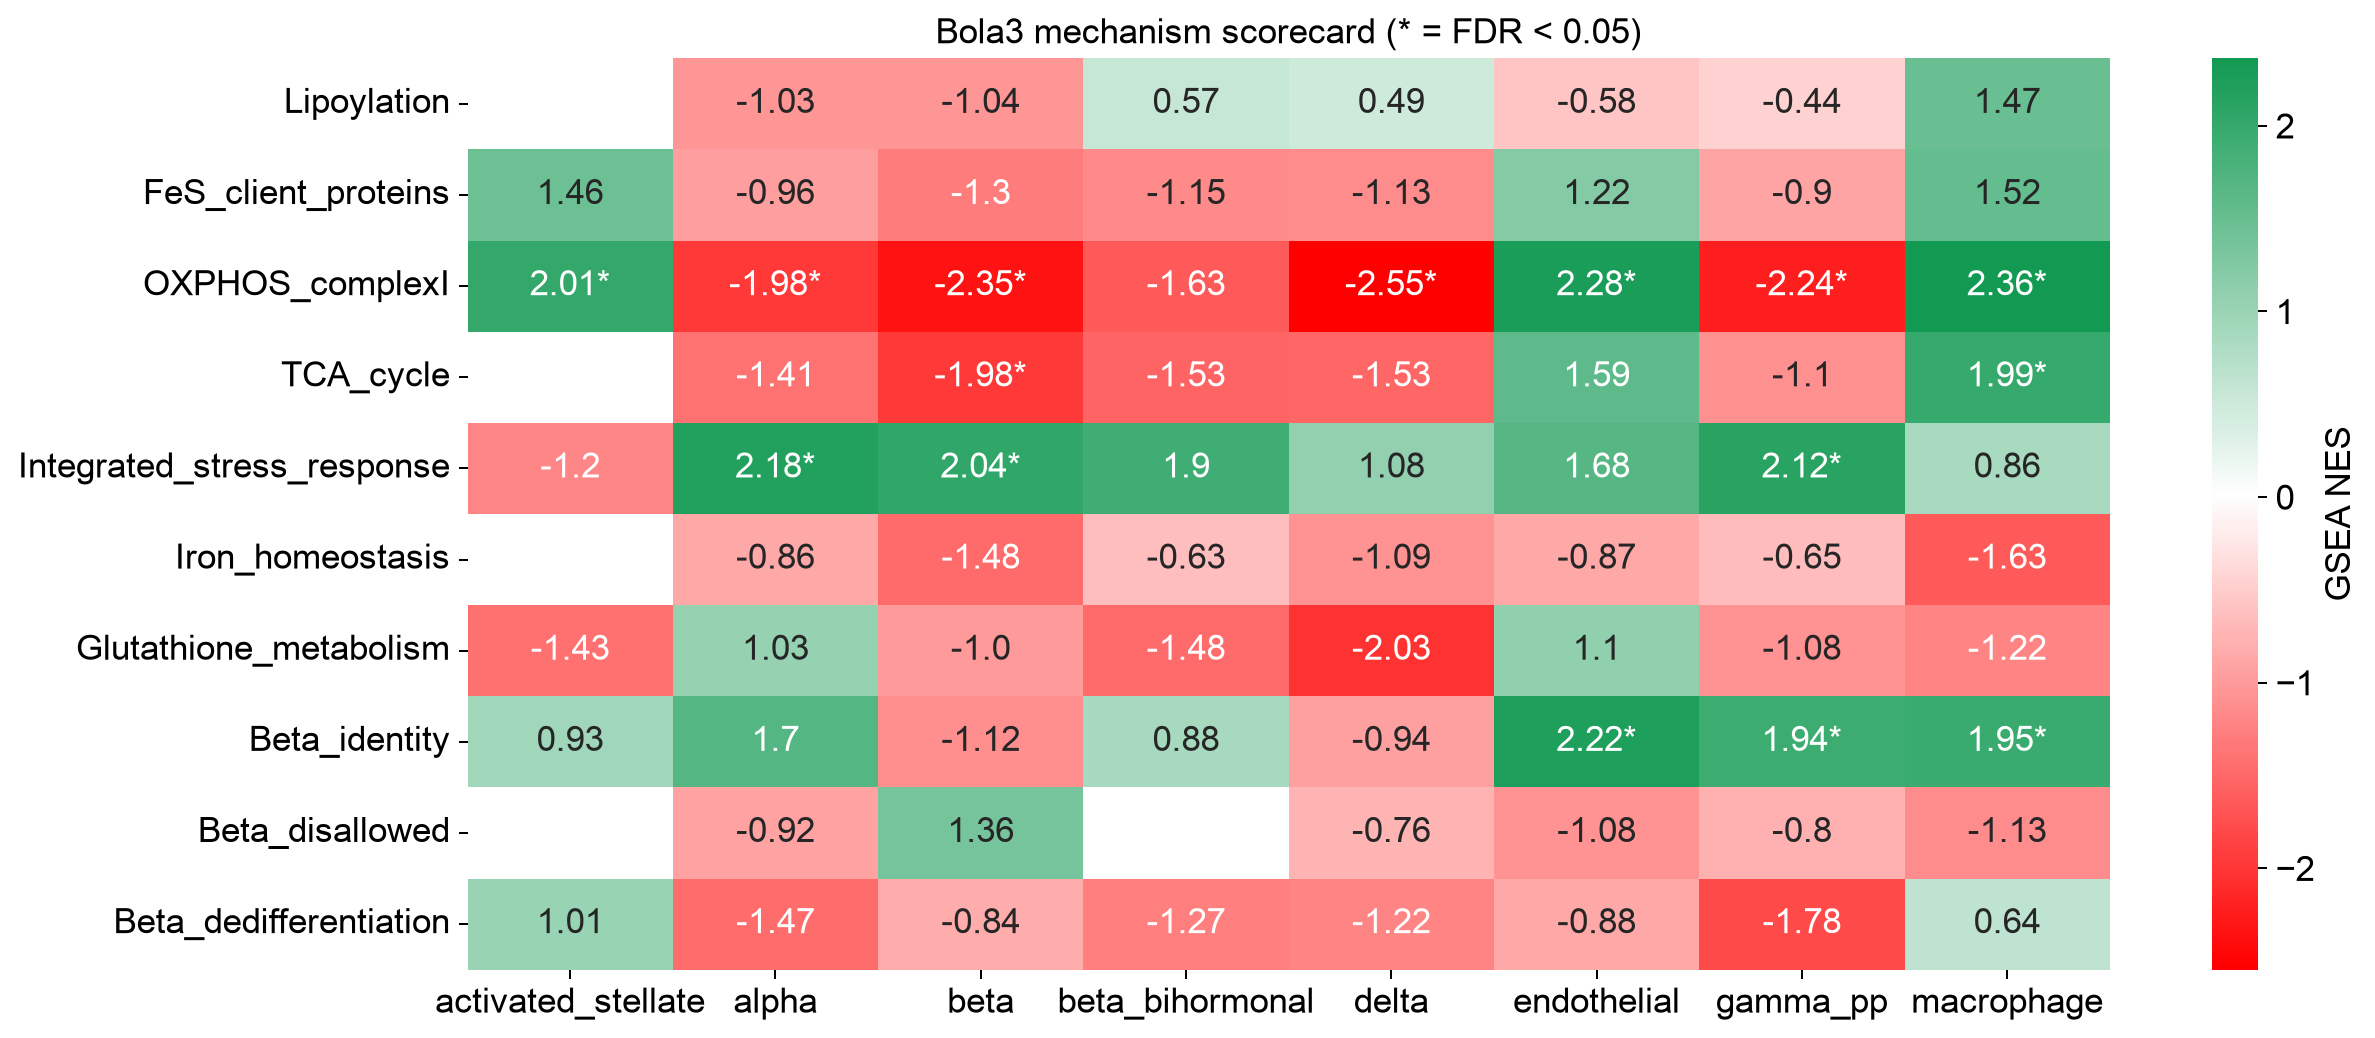

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

EXCLUDE = {"Ferroptosis", "Mitochondrial_UPR", "Oxidative_stress", "Insulin_secretion_coupling"}

score_card = (gsea.dropna(subset=["predicted"])
              .pivot_table(index="gene_set", columns="cell_type", values="norm_score"))
sig_mask = (gsea.dropna(subset=["predicted"])
            .pivot_table(index="gene_set", columns="cell_type", values="FDR")) < 0.05
annot = score_card.round(2).astype(str)
annot = annot.where(~sig_mask, annot + "*")

order = [k for k in DIRECTIONAL_HYPOTHESES if k in score_card.index and k not in EXCLUDE]

custom_cmap = LinearSegmentedColormap.from_list("RedGreen", ["#ff0000", "#ffffff", "#009245"])
fig, ax = plt.subplots(figsize=(1.3 * score_card.shape[1] + 4, 0.45 * len(order) + 1.5))
sns.heatmap(score_card.loc[order], cmap=custom_cmap, center=0, annot=annot.loc[order],
            fmt="", ax=ax, cbar_kws={"label": "GSEA NES"}, linewidths=0)
ax.set_title("Bola3 mechanism scorecard (* = FDR < 0.05)")
ax.set_xlabel(""); ax.set_ylabel("")
ax.grid(False)
fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "06_mechanism_scorecard.png", dpi=300, bbox_inches="tight")
plt.show()

### 6.2 Unbiased enrichment — MSigDB Hallmark

The check on the prior. If something large is happening that the curated sets
do not cover, it shows up here.

Hallmark: 50 sets, 7611 gene memberships


,cell_type,gene_set,norm_score,pvalue,FDR
319,gamma_pp,INTERFERON_ALPHA_RESPONSE,-3.684595,0.000000,0.000000
269,endothelial,INTERFERON_ALPHA_RESPONSE,-3.437299,0.000000,0.000000
320,gamma_pp,INTERFERON_GAMMA_RESPONSE,-3.421092,0.000000,0.000000
370,macrophage,INTERFERON_GAMMA_RESPONSE,-3.402543,0.000000,0.000000
369,macrophage,INTERFERON_ALPHA_RESPONSE,-3.394209,0.000000,0.000000
...,...,...,...,...,...
160,beta_bihormonal,FATTY_ACID_METABOLISM,-1.715808,0.009940,0.049702
98,beta,APICAL_JUNCTION,1.708305,0.000000,0.000000
72,alpha,KRAS_SIGNALING_UP,-1.694238,0.008801,0.033851
175,beta_bihormonal,MYC_TARGETS_V1,-1.685522,0.000000,0.000000


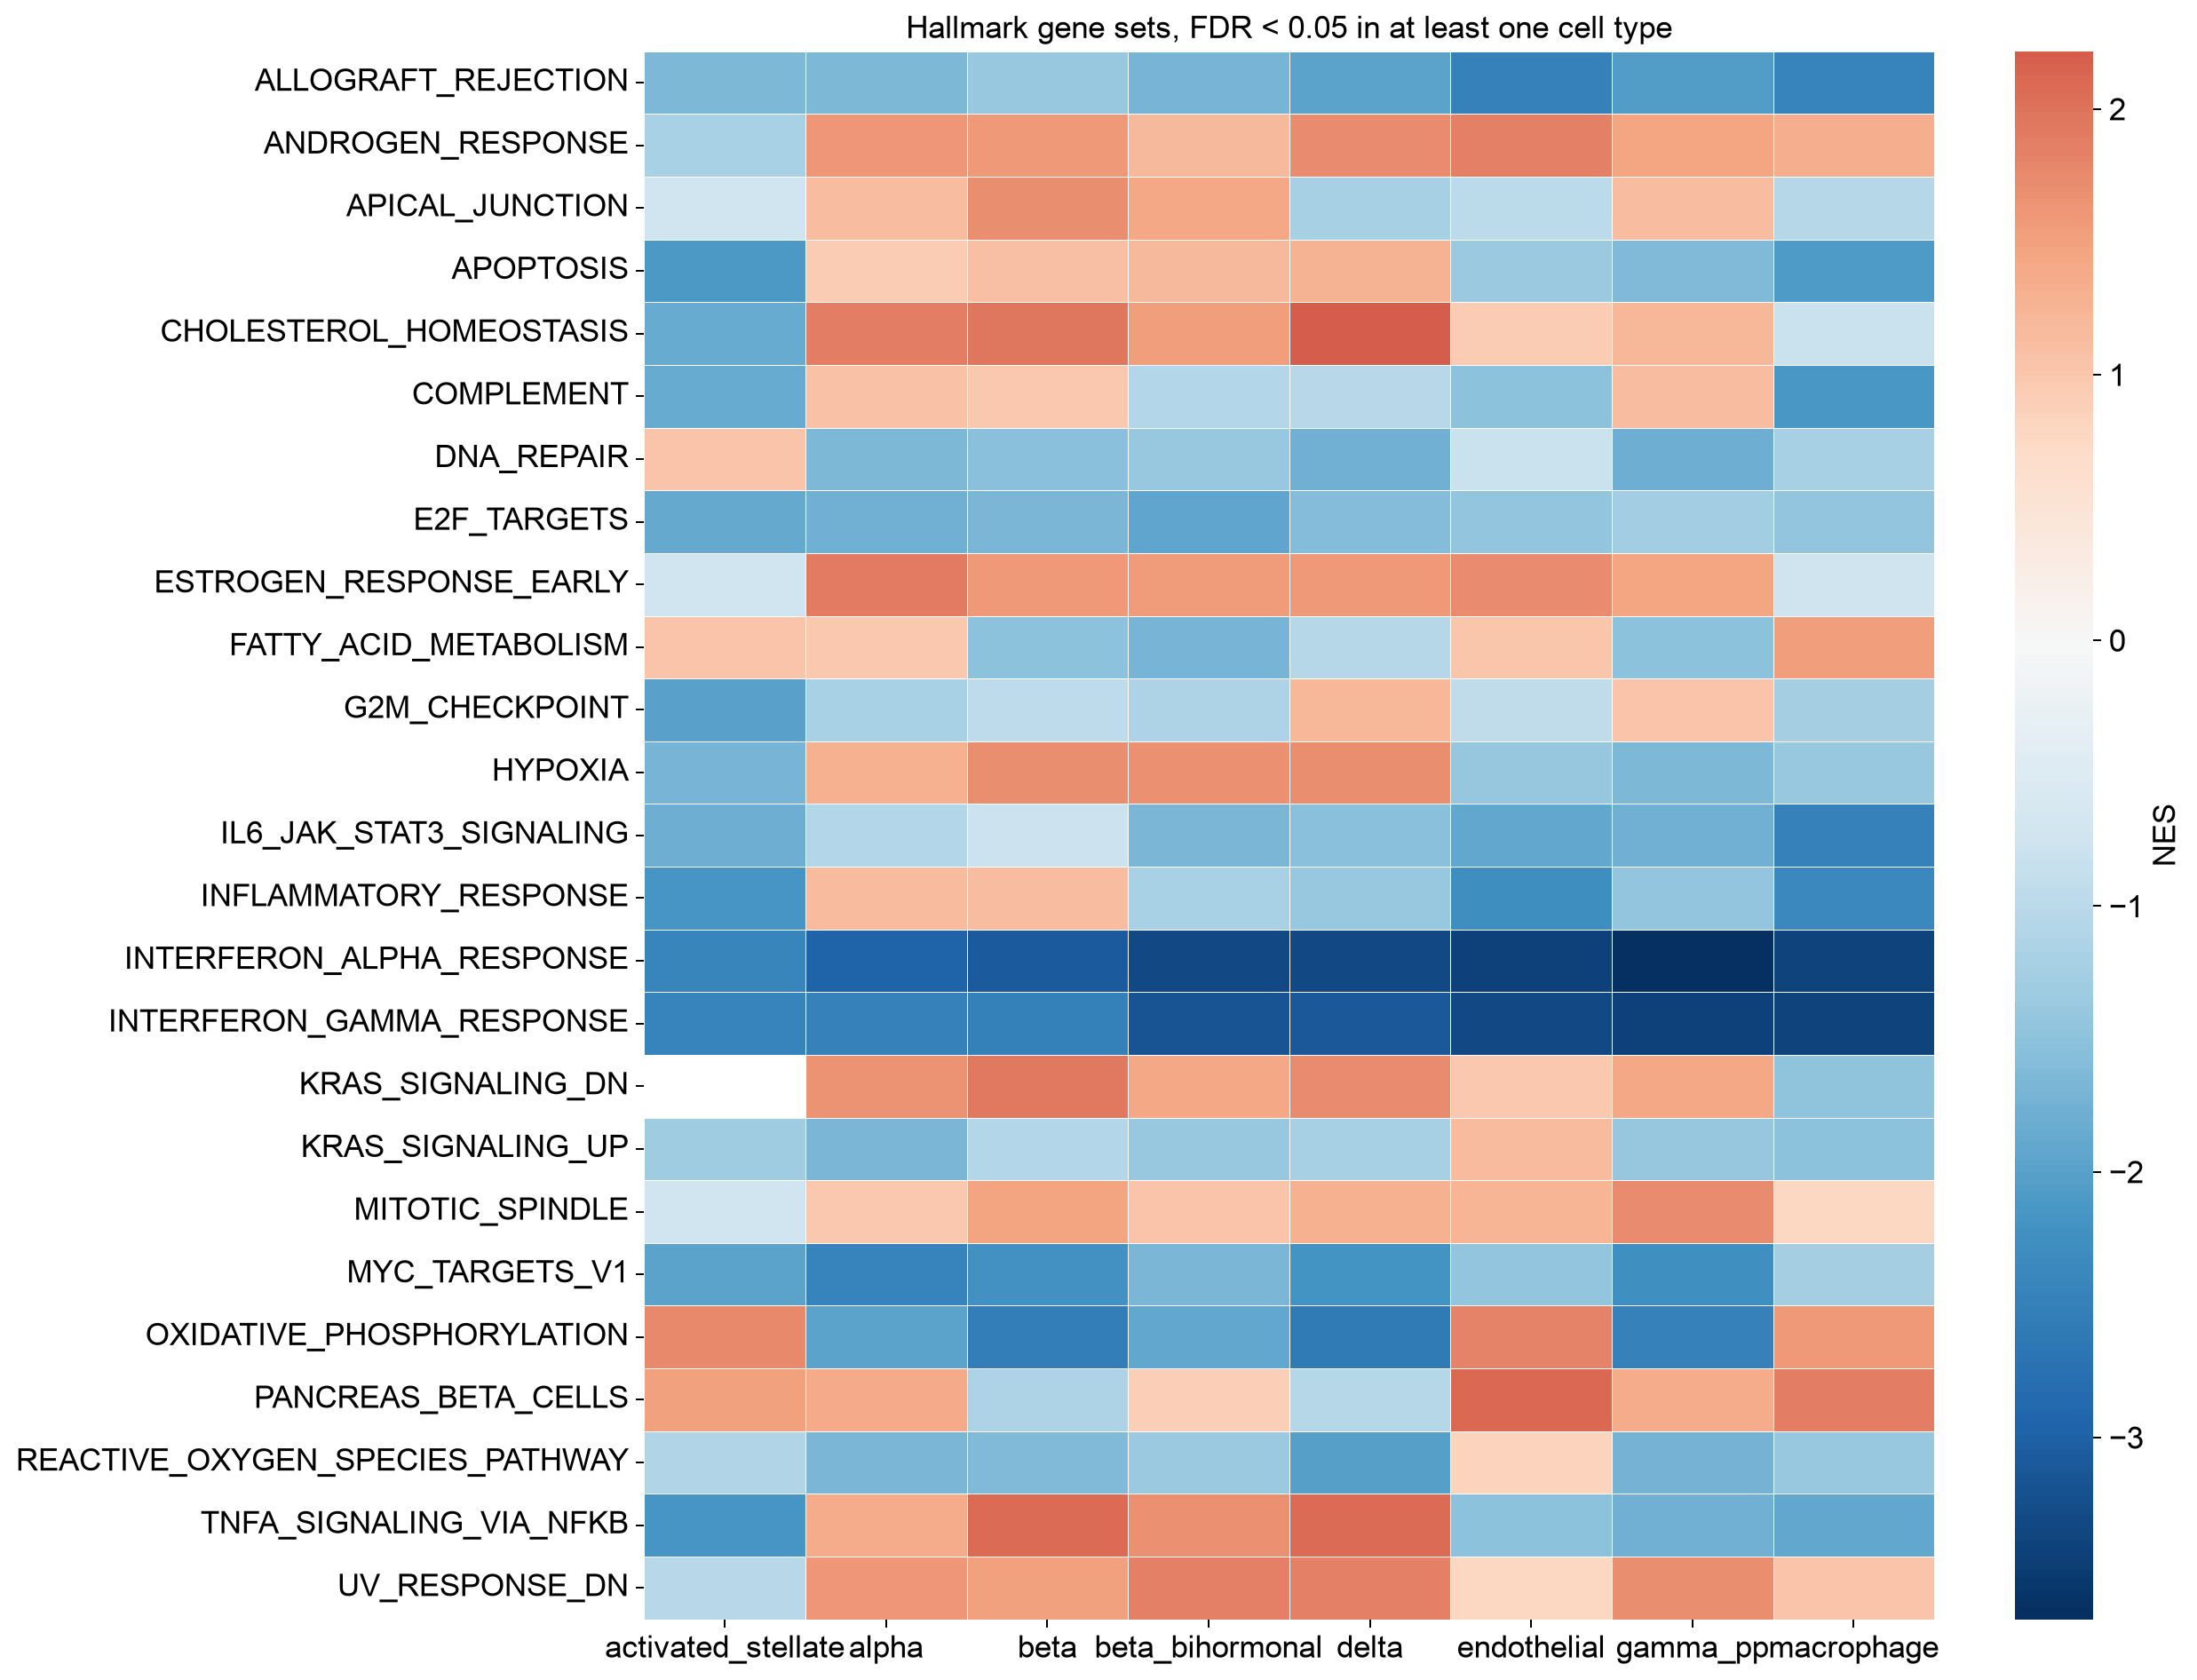

In [14]:
try:
    hallmark = dc.op.hallmark(organism="mouse")
    print(f"Hallmark: {hallmark['source'].nunique()} sets, "
          f"{len(hallmark)} gene memberships")
except Exception as e:
    # dc.op.* downloads from OmniPath, so this needs internet. Offline fallback:
    # download mh.all.v2024.1.Mm.symbols.gmt from gsea-msigdb.org once, then
    #   hallmark = dc.pp.read_gmt("mh.all.v2024.1.Mm.symbols.gmt")
    print(f"could not fetch Hallmark ({e}); skipping section 6.2")
    hallmark = None

if hallmark is not None:
    rows = []
    for ct, sub in de.groupby("cell_type"):
        ranks = sub.dropna(subset=["stat"]).set_index("gene")[["stat"]].T
        ranks.index = [ct]
        try:
            nes, pval = dc.mt.gsea(data=ranks, net=hallmark, tmin=10)
            rows.append(pd.DataFrame({
                "cell_type": ct, "gene_set": nes.columns,
                "norm_score": nes.iloc[0].values, "pvalue": pval.iloc[0].values,
            }))
        except Exception as e:
            print(f"  {ct}: {e}")
    hm = pd.concat(rows, ignore_index=True)
    hm["FDR"] = np.nan
    for ct, idx in hm.groupby("cell_type").groups.items():
        hm.loc[idx, "FDR"] = multipletests(hm.loc[idx, "pvalue"], method="fdr_bh")[1]
    hm.to_csv(cfg.TABLE_DIR / "06_gsea_hallmark.csv", index=False)

    top = (hm[hm.FDR < 0.05].reindex(
        hm[hm.FDR < 0.05].norm_score.abs().sort_values(ascending=False).index)
        .groupby("cell_type").head(8))
    if len(top):
        pivot = hm[hm.gene_set.isin(top.gene_set.unique())].pivot_table(
            index="gene_set", columns="cell_type", values="norm_score")
        fig, ax = plt.subplots(figsize=(1.2 * pivot.shape[1] + 5, 0.35 * len(pivot) + 2))
        sns.heatmap(pivot, cmap="RdBu_r", center=0, ax=ax,
                    cbar_kws={"label": "NES"}, linewidths=0.4)
        ax.set_title("Hallmark gene sets, FDR < 0.05 in at least one cell type")
        ax.set_xlabel(""); ax.set_ylabel("")
        ax.grid(False)
        fig.tight_layout()
        fig.savefig(cfg.FIG_DIR / "06_hallmark_heatmap.png", dpi=300, bbox_inches="tight")
        display(top)

Hallmark: 50 sets, 7611 gene memberships


,cell_type,gene_set,norm_score,pvalue,FDR
319,gamma_pp,INTERFERON_ALPHA_RESPONSE,-3.684595,0.000000,0.000000
269,endothelial,INTERFERON_ALPHA_RESPONSE,-3.437299,0.000000,0.000000
320,gamma_pp,INTERFERON_GAMMA_RESPONSE,-3.421092,0.000000,0.000000
370,macrophage,INTERFERON_GAMMA_RESPONSE,-3.402543,0.000000,0.000000
369,macrophage,INTERFERON_ALPHA_RESPONSE,-3.394209,0.000000,0.000000
...,...,...,...,...,...
160,beta_bihormonal,FATTY_ACID_METABOLISM,-1.715808,0.009940,0.049702
98,beta,APICAL_JUNCTION,1.708305,0.000000,0.000000
72,alpha,KRAS_SIGNALING_UP,-1.694238,0.008801,0.033851
175,beta_bihormonal,MYC_TARGETS_V1,-1.685522,0.000000,0.000000


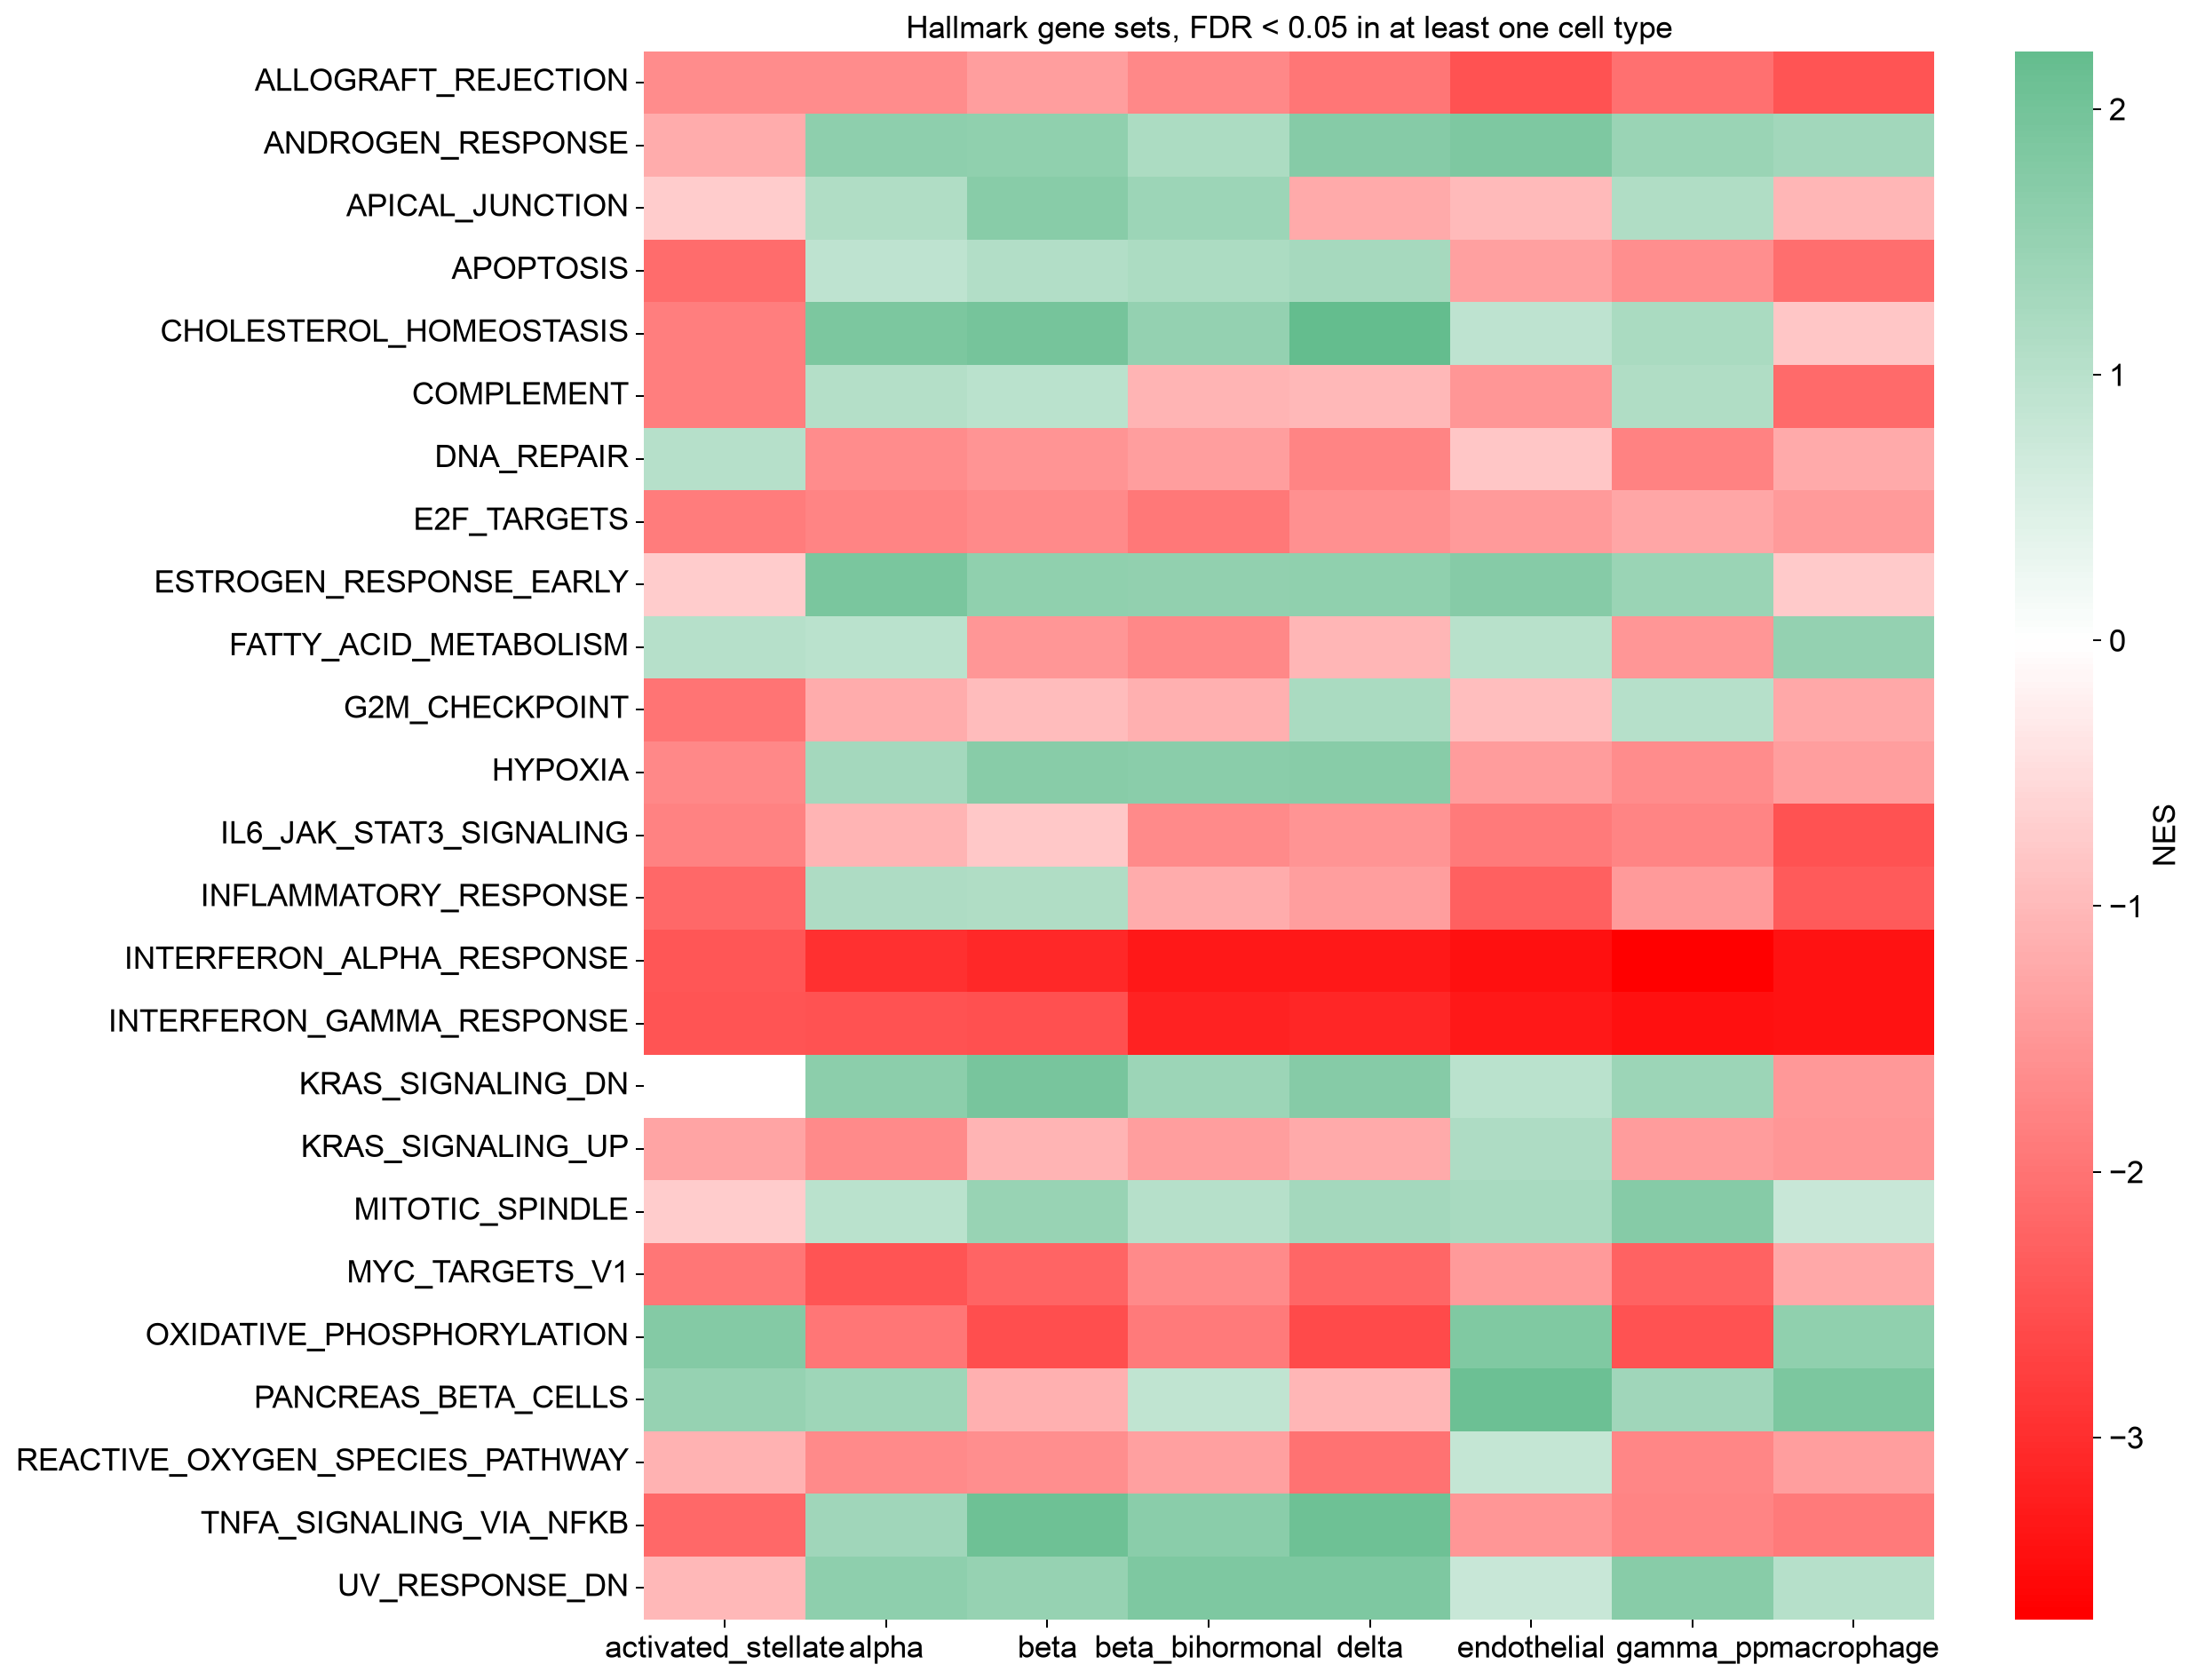

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

try:
    hallmark = dc.op.hallmark(organism="mouse")
    print(f"Hallmark: {hallmark['source'].nunique()} sets, "
          f"{len(hallmark)} gene memberships")
except Exception as e:
    # dc.op.* downloads from OmniPath, so this needs internet. Offline fallback:
    # download mh.all.v2024.1.Mm.symbols.gmt from gsea-msigdb.org once, then
    # hallmark = dc.pp.read_gmt("mh.all.v2024.1.Mm.symbols.gmt")
    print(f"could not fetch Hallmark ({e}); skipping section 6.2")
    hallmark = None

if hallmark is not None:
    rows = []
    for ct, sub in de.groupby("cell_type"):
        ranks = sub.dropna(subset=["stat"]).set_index("gene")[["stat"]].T
        ranks.index = [ct]
        try:
            nes, pval = dc.mt.gsea(data=ranks, net=hallmark, tmin=10)
            rows.append(pd.DataFrame({
                "cell_type": ct,
                "gene_set": nes.columns,
                "norm_score": nes.iloc[0].values,
                "pvalue": pval.iloc[0].values,
            }))
        except Exception as e:
            print(f"  {ct}: {e}")
            
    hm = pd.concat(rows, ignore_index=True)
    hm["FDR"] = np.nan
    for ct, idx in hm.groupby("cell_type").groups.items():
        hm.loc[idx, "FDR"] = multipletests(hm.loc[idx, "pvalue"], method="fdr_bh")[1]
        
    hm.to_csv(cfg.TABLE_DIR / "06_gsea_hallmark.csv", index=False)
    
    top = (hm[hm.FDR < 0.05].reindex(
           hm[hm.FDR < 0.05].norm_score.abs().sort_values(ascending=False).index)
           .groupby("cell_type").head(8))
           
    if len(top):
        pivot = hm[hm.gene_set.isin(top.gene_set.unique())].pivot_table(
            index="gene_set", columns="cell_type", values="norm_score")
            
        fig, ax = plt.subplots(figsize=(1.2 * pivot.shape[1] + 5, 0.35 * len(pivot) + 2))
        
        # 1. Custom colormap blending: Downregulated (Red) -> Neutral (White) -> Upregulated (Green)
        custom_cmap = LinearSegmentedColormap.from_list("RedGreen", ["#ff0000", "#ffffff", "#009245"])
        
        # 2. Applied custom_cmap and set linewidths=0 to remove cell borders
        sns.heatmap(pivot, cmap=custom_cmap, center=0, ax=ax, cbar_kws={"label": "NES"}, linewidths=0)
        
        ax.set_title("Hallmark gene sets, FDR < 0.05 in at least one cell type")
        ax.set_xlabel(""); ax.set_ylabel("")
        ax.grid(False)
        fig.tight_layout()
        fig.savefig(cfg.FIG_DIR / "06_hallmark_heatmap.png", dpi=300, bbox_inches="tight")
        display(top)


### 6.3 Transcription factor activity

`CollecTRI` maps TFs to their target genes, and `dc.mt.ulm` infers each TF's
activity from how coherently its targets moved. This is the direct test of
whether the integrated stress response fired: **Atf4 activity should be up in
the KO**, and it should be up because its targets moved together, not because
`Atf4` transcript itself changed.
This infers each transcription factor's activity from how its targets moved. The key readouts: Atf4 activity up = the integrated stress response genuinely fired (independent of the Atf4 transcript itself), and Mafa/Pdx1/Nkx6-1 activity down = loss of the mature beta identity network. Watch the stress-TF table it prints.

TFs not in the CollecTRI network (skipped): ['Tfeb', 'Rfx6']


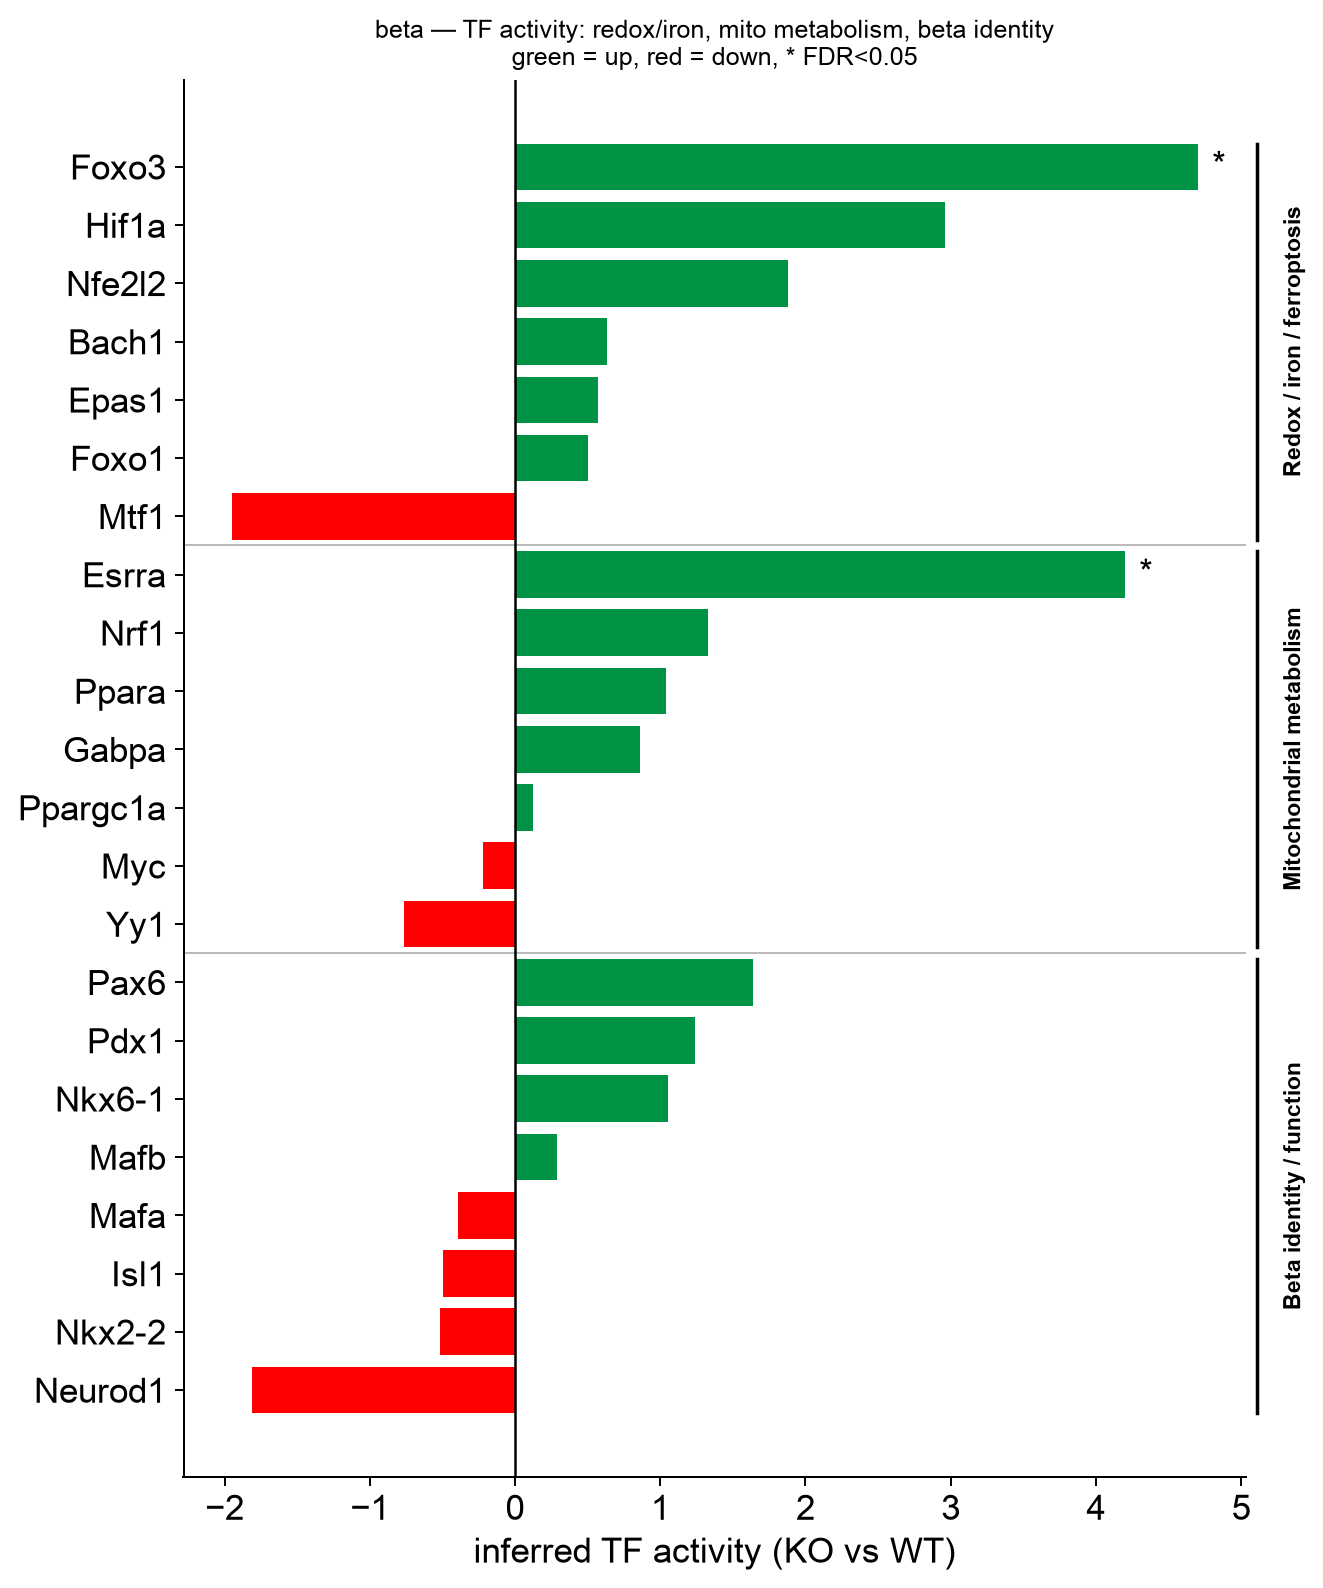

In [20]:
FOCUS_TFS = {
    "Redox / iron / ferroptosis": ["Nfe2l2", "Bach1", "Mtf1", "Hif1a", "Epas1", "Foxo1", "Foxo3", "Tfeb"],
    "Mitochondrial metabolism":   ["Ppargc1a", "Nrf1", "Gabpa", "Esrra", "Yy1", "Myc", "Ppara"],
    "Beta identity / function":   ["Mafa", "Pdx1", "Nkx6-1", "Neurod1", "Pax6", "Nkx2-2", "Mafb", "Rfx6", "Isl1"],
}
flat = [t for v in FOCUS_TFS.values() for t in v]
cat_of = {t: c for c, v in FOCUS_TFS.items() for t in v}

fb = tf[(tf.cell_type == FOCUS) & (tf.TF.isin(flat))].copy()
missing = [t for t in flat if t not in set(tf.TF)]
if missing: print("TFs not in the CollecTRI network (skipped):", missing)
fb["cat"] = fb.TF.map(cat_of)
fb = fb.sort_values(["cat", "activity"])

colours = ["#009245" if a > 0 else "#ff0000" for a in fb.activity]     # green up / red down
fig, ax = plt.subplots(figsize=(7.6, 0.34 * len(fb) + 1.6))
ax.barh(range(len(fb)), fb.activity, color=colours)
ax.set_yticks(range(len(fb))); ax.set_yticklabels(fb.TF)
for i, (a, fdr) in enumerate(zip(fb.activity, fb.FDR)):
    if fdr < 0.05:
        ax.text(a + np.sign(a) * 0.1, i, "*", va="center", ha="left" if a > 0 else "right", fontsize=14)
# separators between category blocks
cats_by_pos = fb["cat"].tolist()
for i in range(1, len(cats_by_pos)):
    if cats_by_pos[i] != cats_by_pos[i - 1]:
        ax.axhline(i - 0.5, color="#bbbbbb", lw=0.8)
# side labels + brackets in the right margin
for cat in dict.fromkeys(cats_by_pos):
    ys = [i for i, c in enumerate(cats_by_pos) if c == cat]
    ax.plot([1.01, 1.01], [min(ys) - 0.4, max(ys) + 0.4], transform=ax.get_yaxis_transform(),
            color="k", lw=1.4, clip_on=False)
    ax.text(1.035, np.mean(ys), cat, transform=ax.get_yaxis_transform(),
            rotation=90, va="center", ha="left", fontweight="bold", fontsize=9)
ax.axvline(0, c="k", lw=1)
ax.set_xlabel("inferred TF activity (KO vs WT)")
ax.set_title(f"{FOCUS} — TF activity: redox/iron, mito metabolism, beta identity\n"
             "green = up, red = down, * FDR<0.05", fontsize=10)
ax.grid(False)
sns.despine(); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / f"06_tf_activity_focus_{FOCUS}.png", dpi=300, bbox_inches="tight")
plt.show()

### 6.4 Module scores at single-cell resolution

Everything above is pseudobulk, which answers "did the average KO cell differ
from the average WT cell". Scoring the modules per cell answers a different
question: **is the response uniform, or is a subset of cells carrying it?**

A bimodal ISR score in the KO — most beta cells normal, a subpopulation
strongly stressed — is a materially different finding from a uniform shift, and
suggests a threshold effect or a stochastic tipping point. This is the analysis
that makes single-cell data worth having done at all.

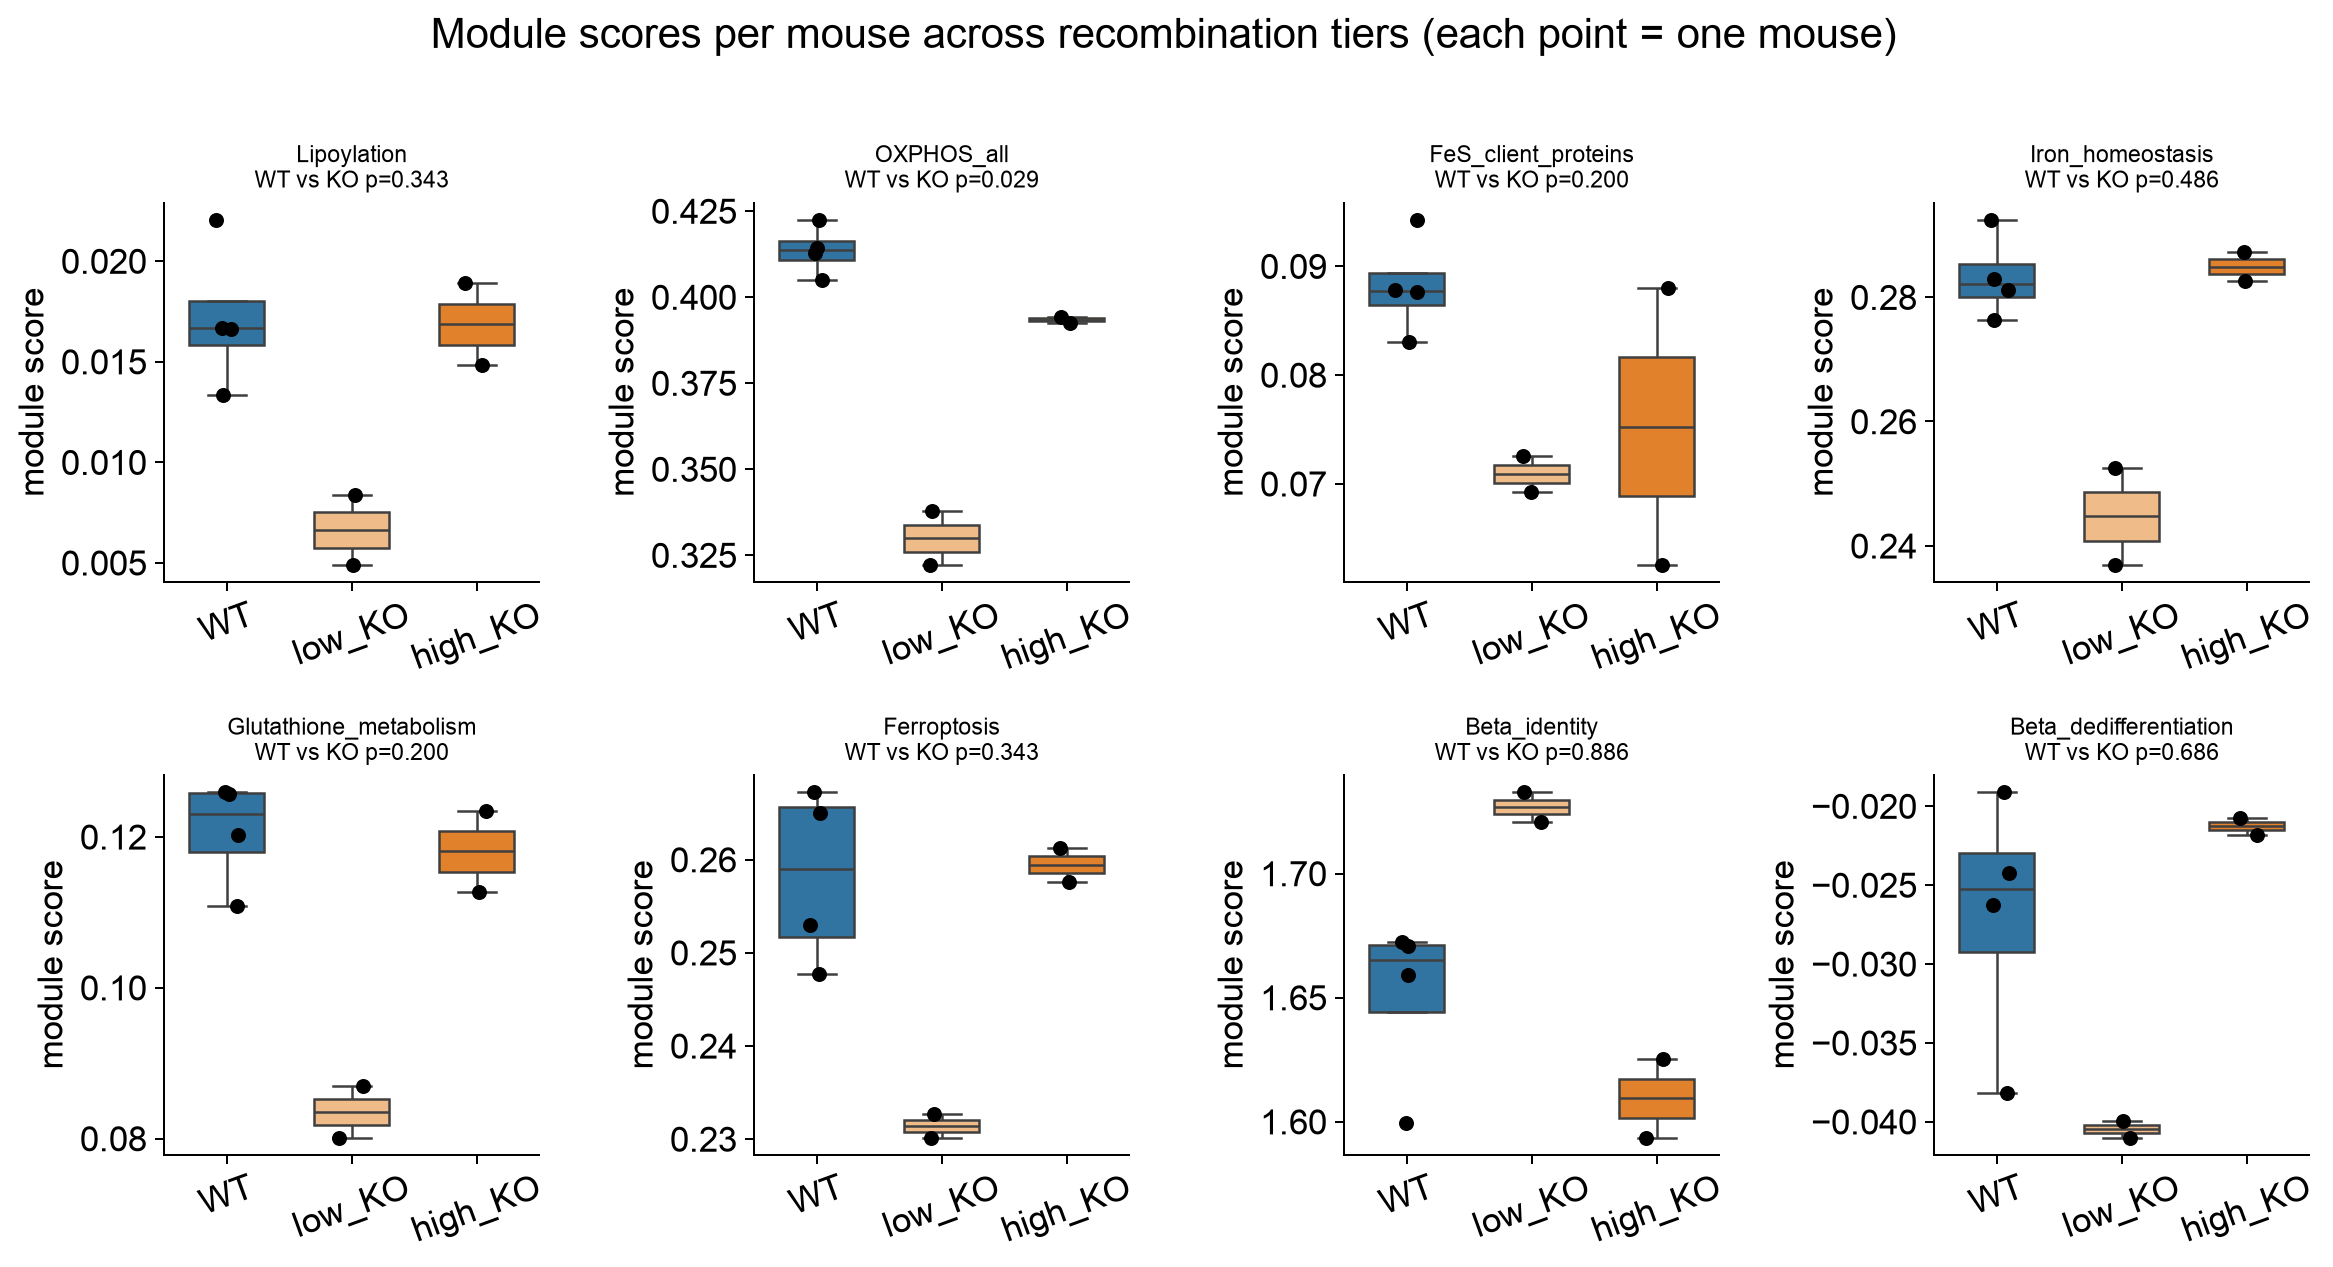

In [24]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import mannwhitneyu

KEY = ["Lipoylation", "OXPHOS_all", "FeS_client_proteins",
       "Iron_homeostasis", "Glutathione_metabolism", "Ferroptosis",
       "Beta_identity", "Beta_dedifferentiation"]
KEY = [k for k in KEY if f"m_{k}" in adata.obs]

beta_cells = adata.obs[adata.obs["cell_type"] == "beta"].copy()
per_mouse = (beta_cells.groupby(["sample_id", "recomb_tier"], observed=True)
             [[f"m_{k}" for k in KEY]].mean().reset_index())
tier_order = ["WT", "low_KO", "high_KO"]
tier_pal = {"WT": "#1f77b4", "low_KO": "#ffbb78", "high_KO": "#ff7f0e"}

ncol = 4; nrow = int(np.ceil(len(KEY) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.3 * ncol, 3.5 * nrow))
for ax, k in zip(axes.flat, KEY):
    col = f"m_{k}"
    sns.boxplot(data=per_mouse, x="recomb_tier", y=col, order=tier_order, palette=tier_pal,
                hue="recomb_tier", legend=False, width=0.6, fliersize=0, ax=ax)
    sns.stripplot(data=per_mouse, x="recomb_tier", y=col, order=tier_order, color="k", size=6, ax=ax)
    wt = per_mouse.loc[per_mouse.recomb_tier == "WT", col]
    ko = per_mouse.loc[per_mouse.recomb_tier != "WT", col]
    p = mannwhitneyu(wt, ko).pvalue if len(wt) and len(ko) else np.nan
    ax.set_title(f"{k}\nWT vs KO p={p:.3f}", fontsize=9)
    ax.set_xlabel(""); ax.set_ylabel("module score")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(False)
for ax in axes.flat[len(KEY):]:
    ax.axis("off")

fig.suptitle("Module scores per mouse across recombination tiers (each point = one mouse)", y=1.01)
sns.despine(fig); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "06_module_scores_by_tier.png", dpi=300, bbox_inches="tight")
plt.show()

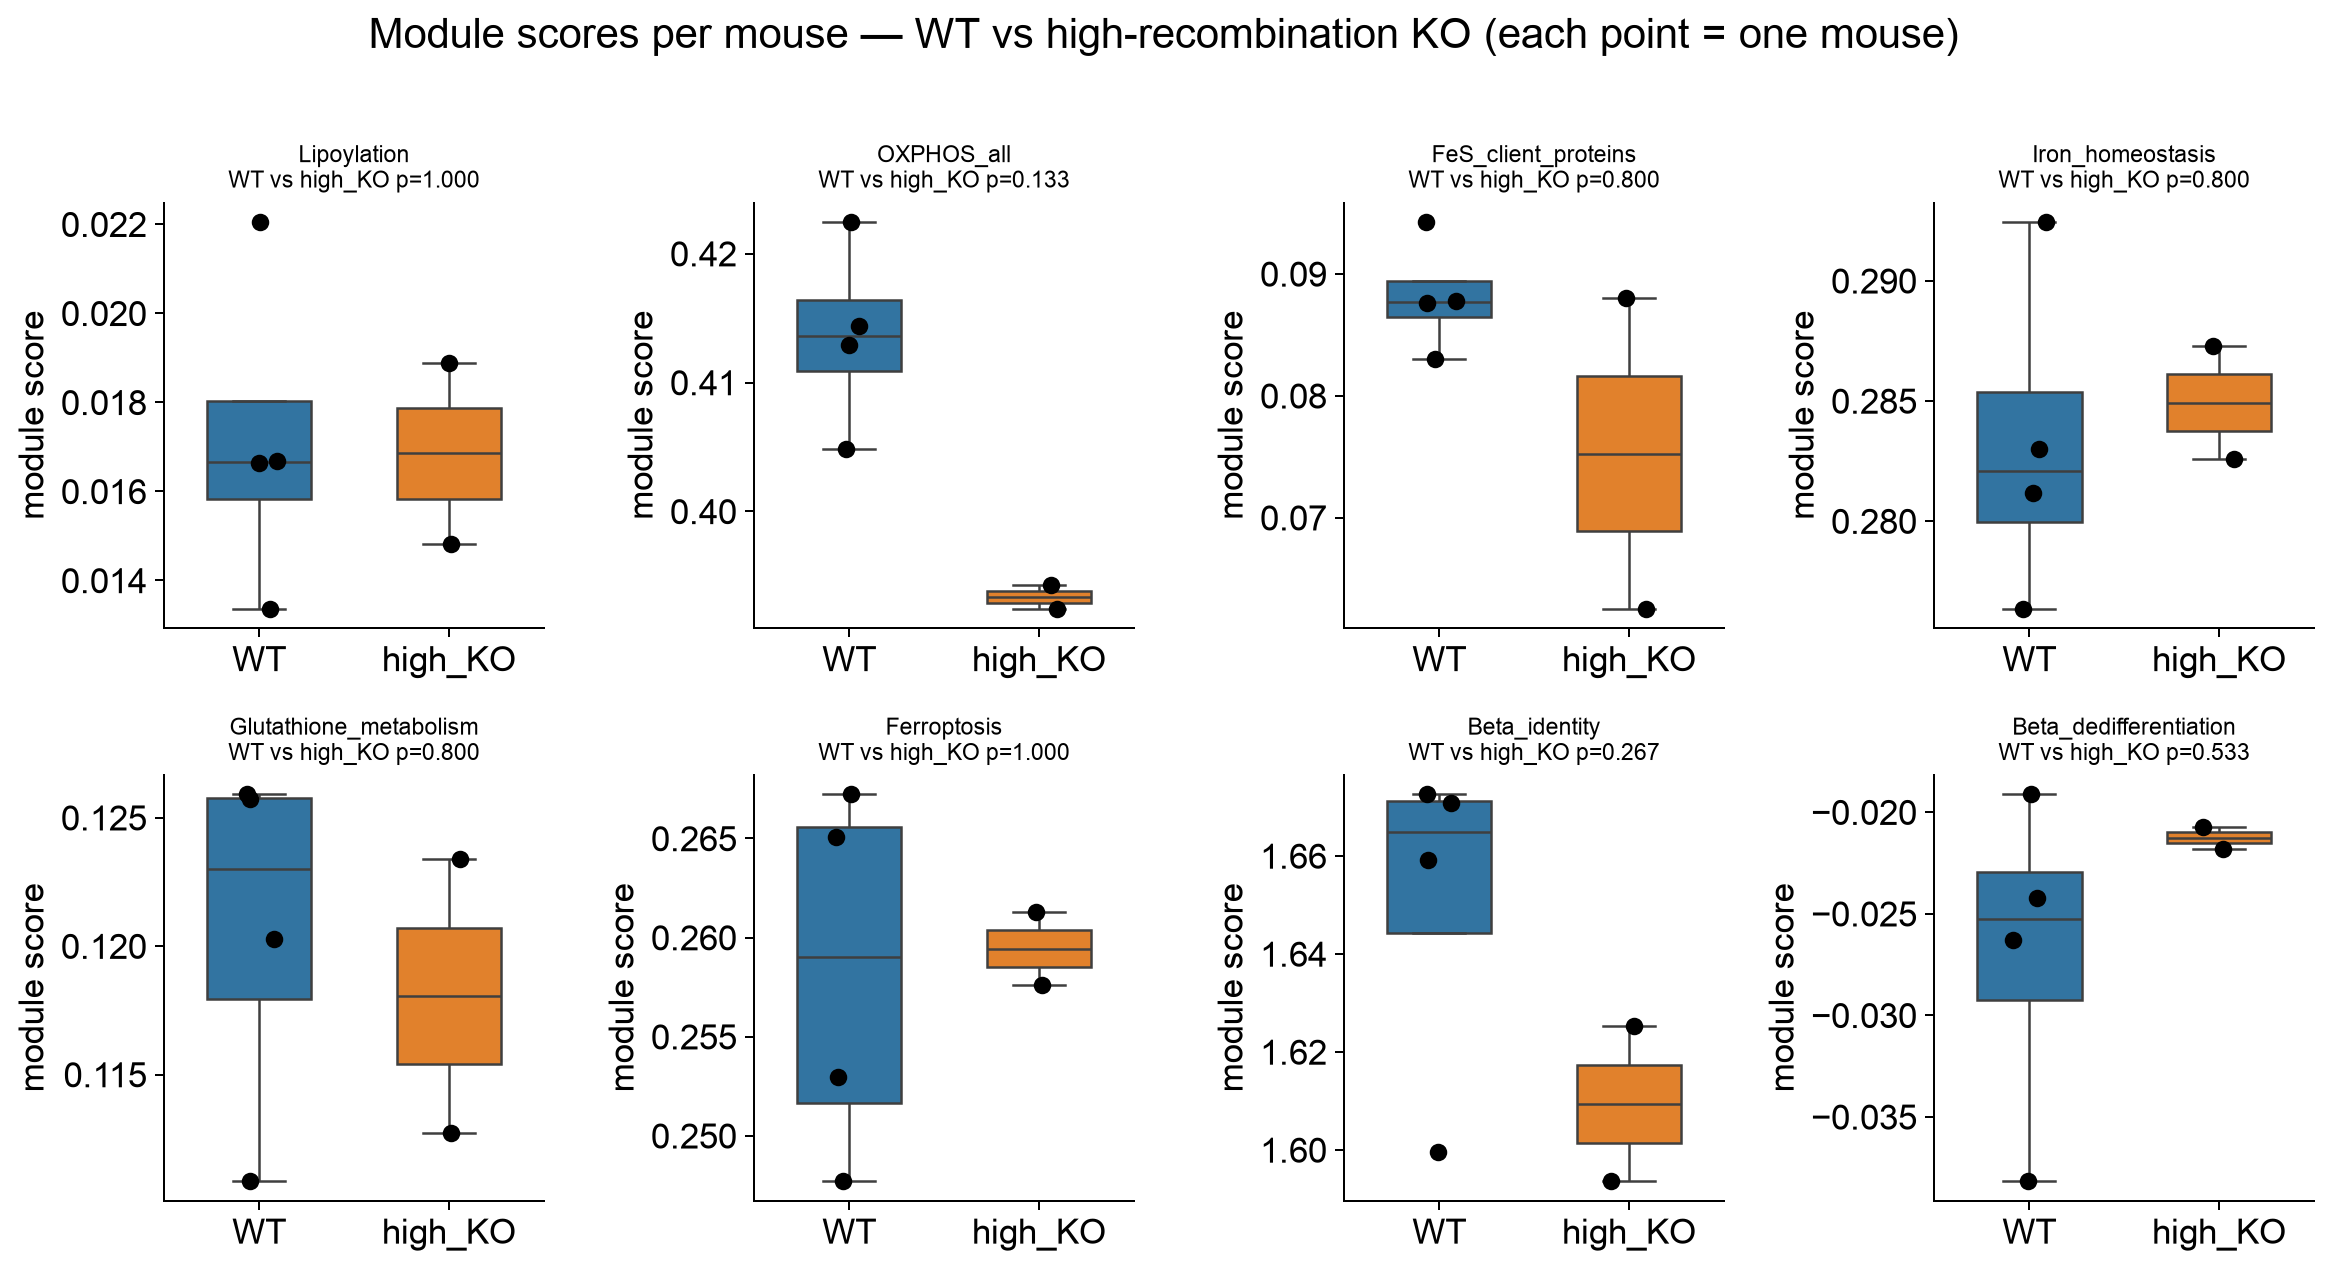

In [27]:
import numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import mannwhitneyu

sub = per_mouse[per_mouse.recomb_tier.isin(["WT", "high_KO"])].copy()
# Reset the categorical levels to only include the filtered categories
sub['recomb_tier'] = sub['recomb_tier'].cat.remove_unused_categories()

order = ["WT", "high_KO"]
pal = {"WT": "#1f77b4", "high_KO": "#ff7f0e"}

ncol = 4; nrow = int(np.ceil(len(KEY) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.3 * ncol, 3.5 * nrow))
for ax, k in zip(axes.flat, KEY):
    col = f"m_{k}"
    sns.boxplot(data=sub, x="recomb_tier", y=col, order=order, palette=pal,
                hue="recomb_tier", legend=False, width=0.55, fliersize=0, ax=ax)
    sns.stripplot(data=sub, x="recomb_tier", y=col, order=order, color="k", size=7, ax=ax)
    w = sub.loc[sub.recomb_tier == "WT", col]; h = sub.loc[sub.recomb_tier == "high_KO", col]
    p = mannwhitneyu(w, h).pvalue
    ax.set_title(f"{k}\nWT vs high_KO p={p:.3f}", fontsize=9)
    ax.set_xlabel(""); ax.set_ylabel("module score")
    ax.grid(False)
for ax in axes.flat[len(KEY):]:
    ax.axis("off")
fig.suptitle("Module scores per mouse — WT vs high-recombination KO (each point = one mouse)", y=1.01)
sns.despine(fig); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "06_module_scores_WT_vs_highKO.png", dpi=300, bbox_inches="tight")
plt.show()

### Is the stressed population a discrete subset?

           mean   std
genotype             
WT         5.02  1.93
KO        12.14  6.46


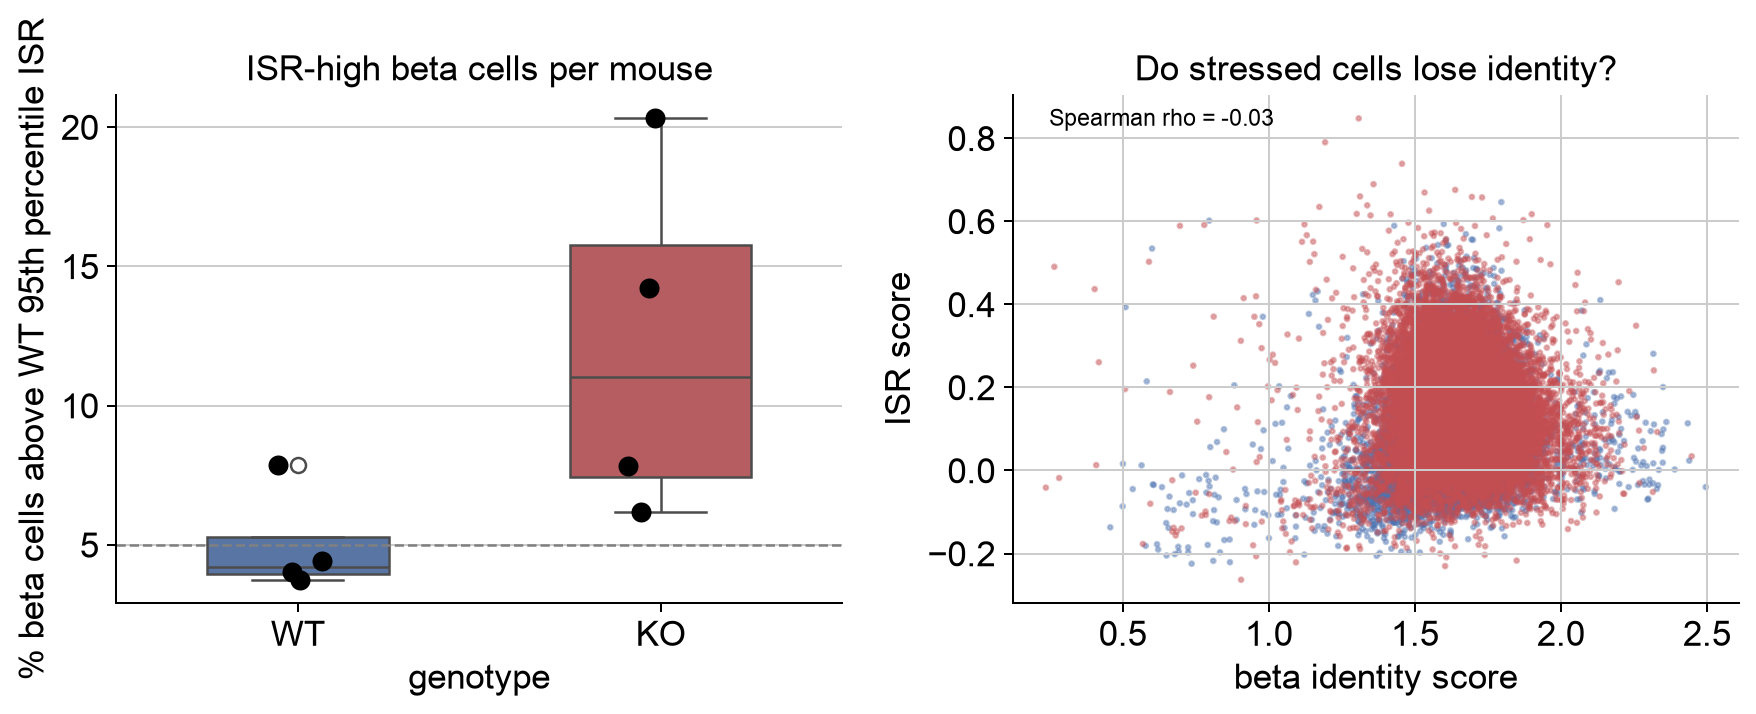

In [28]:
if "m_Integrated_stress_response" in adata.obs:
    beta_cells = adata.obs[adata.obs["cell_type"] == "beta"].copy()
    thresh = beta_cells.loc[beta_cells.genotype == "WT",
                            "m_Integrated_stress_response"].quantile(0.95)
    beta_cells["ISR_high"] = beta_cells["m_Integrated_stress_response"] > thresh

    per_sample = (beta_cells.groupby(["sample_id", "genotype"], observed=True)["ISR_high"]
                  .mean().mul(100).reset_index())
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    sns.boxplot(data=per_sample, x="genotype", y="ISR_high", ax=axes[0],
                palette=PALETTE, width=0.5, hue="genotype", legend=False)
    sns.stripplot(data=per_sample, x="genotype", y="ISR_high", ax=axes[0],
                  color="k", size=8)
    axes[0].set_ylabel("% beta cells above WT 95th percentile ISR")
    axes[0].axhline(5, ls="--", c="grey", lw=1)
    axes[0].set_title("ISR-high beta cells per mouse")

    axes[1].scatter(beta_cells["m_Beta_identity"],
                    beta_cells["m_Integrated_stress_response"],
                    c=[PALETTE[g] for g in beta_cells["genotype"]], s=3, alpha=0.4,
                    rasterized=True)
    axes[1].set_xlabel("beta identity score")
    axes[1].set_ylabel("ISR score")
    axes[1].set_title("Do stressed cells lose identity?")
    from scipy.stats import spearmanr

    r, p = spearmanr(beta_cells["m_Beta_identity"],
                     beta_cells["m_Integrated_stress_response"])
    axes[1].annotate(f"Spearman rho = {r:.2f}", (0.05, 0.94),
                     xycoords="axes fraction", fontsize=9)
    sns.despine(fig); fig.tight_layout()
    fig.savefig(cfg.FIG_DIR / "06_isr_subpopulation.png", dpi=300, bbox_inches="tight")

    print(per_sample.groupby("genotype", observed=True)["ISR_high"]
          .agg(["mean", "std"]).round(2).to_string())

### 6.5 The summary figure

One panel per link in the mechanistic chain, in the order the mechanism
predicts them, so the figure reads as an argument rather than a gallery.

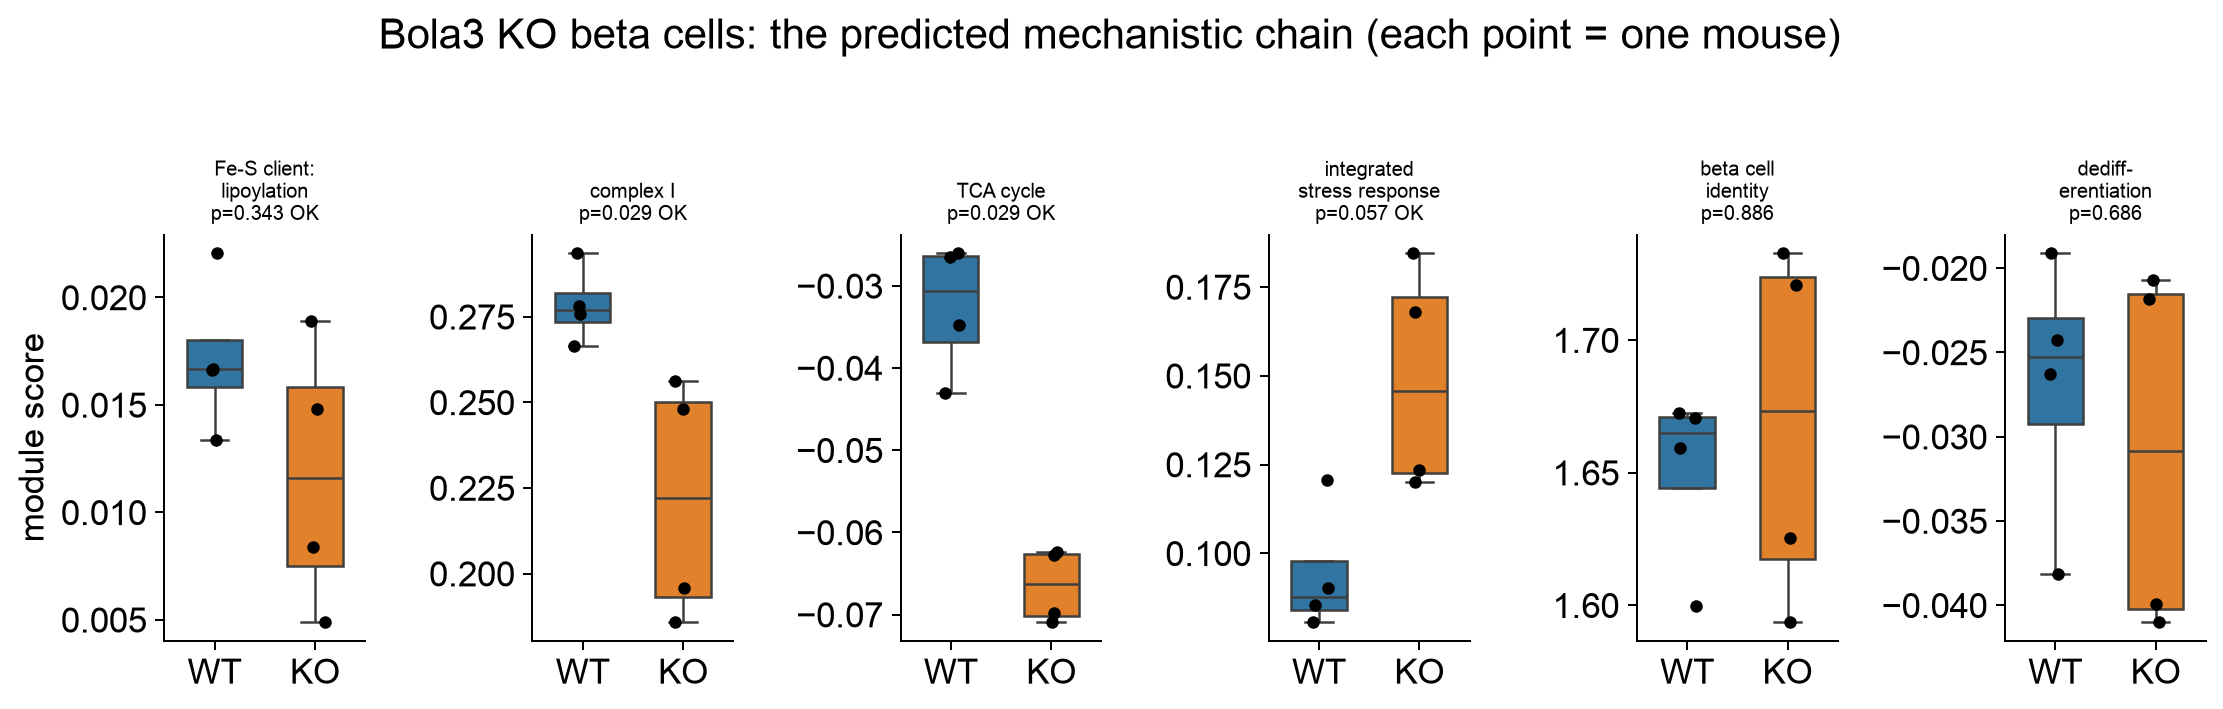

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import mannwhitneyu

chain = [("Lipoylation", "Fe-S client:\nlipoylation"), ("OXPHOS_complexII", "complex II\n(SDH)"), ("OXPHOS_complexI", "complex I"), ("TCA_cycle", "TCA cycle"), ("Integrated_stress_response", "integrated\nstress response"), ("Beta_identity", "beta cell\nidentity"), ("Beta_dedifferentiation", "dediff-\nerentiation")] 
chain = [(k, lab) for k, lab in chain if f"m_{k}" in adata.obs] 

beta_cells = adata.obs[adata.obs["cell_type"] == "beta"] 
per_sample = (beta_cells.groupby(["sample_id", "genotype"], observed=True) [[f"m_{k}" for k, _ in chain]].mean().reset_index()) 

# Define the custom color configuration for the groups
CUSTOM_PALETTE = {
    "WT": "#1f77b4",  # Blue
    "KO": "#ff7f0e"   # Orange
}

fig, axes = plt.subplots(1, len(chain), figsize=(2.1 * len(chain), 3.8), sharey=False) 

for ax, (key, label) in zip(np.atleast_1d(axes), chain): 
    # Turn off the background gridlines
    ax.grid(False)
    
    col = f"m_{key}" 
    
    # Swapped global PALETTE with CUSTOM_PALETTE
    sns.boxplot(data=per_sample, x="genotype", y=col, ax=ax, palette=CUSTOM_PALETTE, width=0.55, hue="genotype", legend=False, fliersize=0) 
    sns.stripplot(data=per_sample, x="genotype", y=col, ax=ax, color="k", size=5) 
    
    w = per_sample.loc[per_sample.genotype == "WT", col] 
    k_ = per_sample.loc[per_sample.genotype == "KO", col] 
    p = mannwhitneyu(w, k_).pvalue 
    
    pred = DIRECTIONAL_HYPOTHESES.get(key, "") 
    obs = "up" if k_.mean() > w.mean() else "down" 
    tick = " OK" if pred == obs else "" 
    
    ax.set_title(f"{label}\np={p:.3f}{tick}", fontsize=8) 
    ax.set_xlabel(""); ax.set_ylabel("module score" if ax is np.atleast_1d(axes)[0] else "") 

fig.suptitle("Bola3 KO beta cells: the predicted mechanistic chain " "(each point = one mouse)", y=1.04) 
sns.despine(fig); fig.tight_layout() 
fig.savefig(cfg.FIG_DIR / "06_mechanism_chain.png", dpi=300, bbox_inches="tight")


adata.write_h5ad(cfg.DATA_DIR / "06_scored.h5ad")

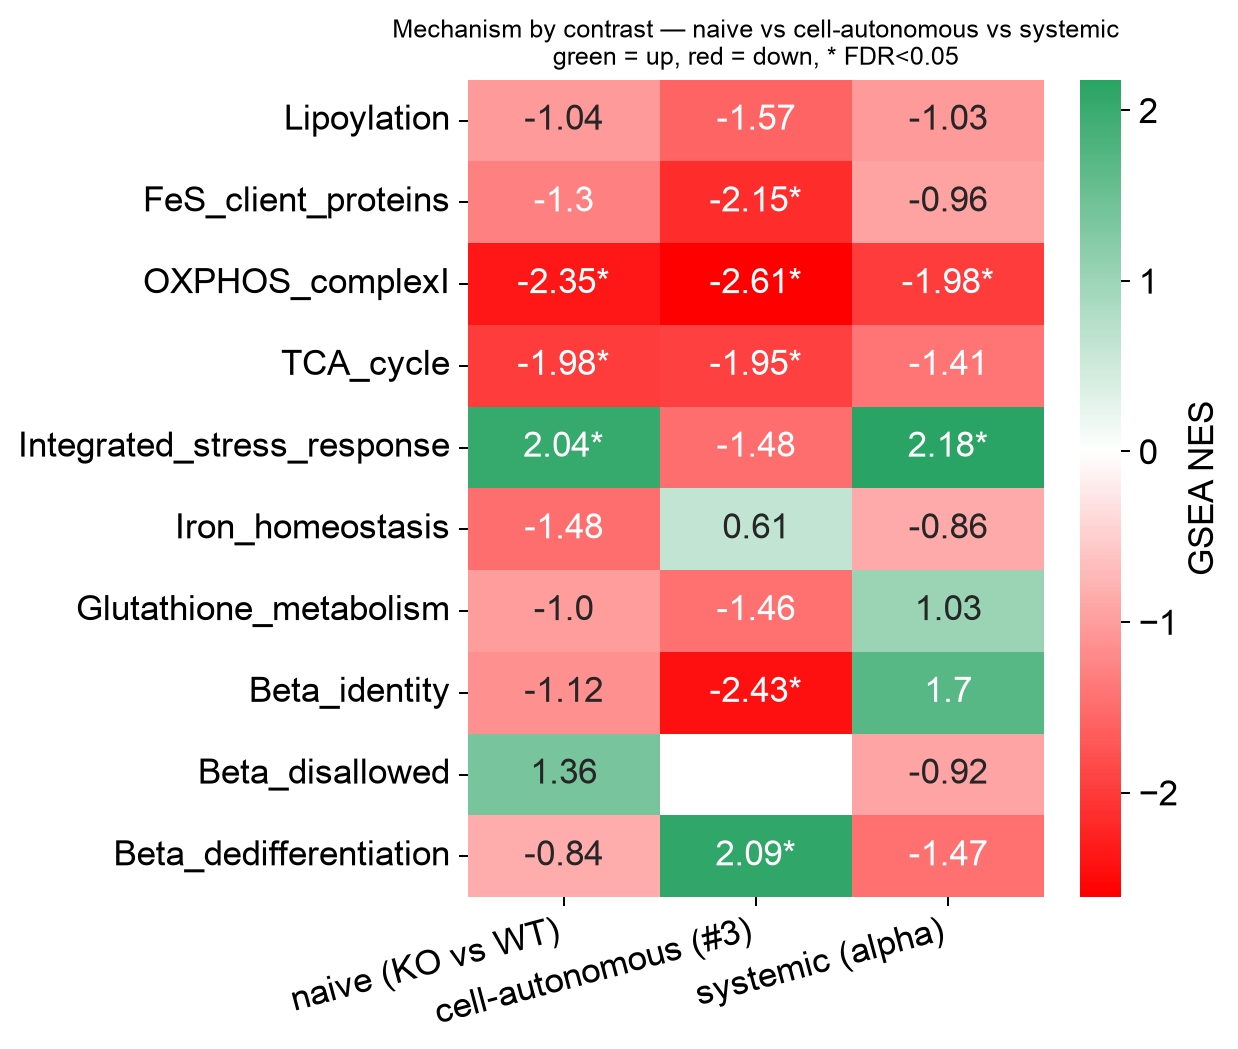

In [37]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns 
from matplotlib.colors import LinearSegmentedColormap 
from statsmodels.stats.multitest import multipletests 

def ranks_of(res): 
    r = res.dropna(subset=["stat"]).copy() 
    if "gene" in r.columns: 
        r = r.set_index("gene") 
    return r["stat"] 

res3 = pd.read_csv(cfg.TABLE_DIR / "05_beta_moved_vs_nonmoved.csv") # cell-autonomous, from disk 

contrasts = { 
    "naive (KO vs WT)": ranks_of(de[de.cell_type == "beta"]), 
    "cell-autonomous (#3)": ranks_of(res3), 
    "systemic (alpha)": ranks_of(de[de.cell_type == "alpha"]), # alpha never recombined 
} 

rows = [] 
for label, ranks in contrasts.items(): 
    r = pd.DataFrame(ranks).T; r.index = [label] 
    nes, pval = dc.mt.gsea(data=r, net=net, tmin=5) 
    rows.append(pd.DataFrame({"contrast": label, "gene_set": nes.columns, "nes": nes.iloc[0].values, "p": pval.iloc[0].values})) 

g3 = pd.concat(rows, ignore_index=True) 
g3["FDR"] = np.nan 
for c, idx in g3.groupby("contrast").groups.items(): 
    g3.loc[idx, "FDR"] = multipletests(g3.loc[idx, "p"], method="fdr_bh")[1] 

g3["predicted"] = g3.gene_set.map(DIRECTIONAL_HYPOTHESES) 
g3.to_csv(cfg.TABLE_DIR / "06_gsea_three_contrasts.csv", index=False) 
EXCLUDE = {"Ferroptosis", "Mitochondrial_UPR", "Oxidative_stress", "Insulin_secretion_coupling"}


cols = ["naive (KO vs WT)", "cell-autonomous (#3)", "systemic (alpha)"] 
nes_p = g3.dropna(subset=["predicted"]).pivot_table(index="gene_set", columns="contrast", values="nes")[cols] 
fdr_p = g3.dropna(subset=["predicted"]).pivot_table(index="gene_set", columns="contrast", values="FDR")[cols] 
order = [k for k in DIRECTIONAL_HYPOTHESES if k in nes_p.index and k not in EXCLUDE]
annot = nes_p.round(2).astype(str).where(~(fdr_p < 0.05), nes_p.round(2).astype(str) + "*") 

cmap = LinearSegmentedColormap.from_list("rg", ["#ff0000", "#ffffff", "#009245"]) 
fig, ax = plt.subplots(figsize=(7, 0.45 * len(order) + 1.6)) 

# Changed linewidths to 0 to completely remove the borders between cells
sns.heatmap(nes_p.loc[order], cmap=cmap, center=0, annot=annot.loc[order], fmt="", linewidths=0, cbar_kws={"label": "GSEA NES"}, ax=ax) 

ax.set_title("Mechanism by contrast — naive vs cell-autonomous vs systemic\n" "green = up, red = down, * FDR<0.05", fontsize=10) 
ax.grid(False) 
ax.set_xlabel(""); ax.set_ylabel("") 
plt.setp(ax.get_xticklabels(), rotation=15, ha="right") 

fig.tight_layout(); fig.savefig(cfg.FIG_DIR / "06_scorecard_by_contrast.png", dpi=300, bbox_inches="tight") 
plt.show()

### Beta Pseudotime

38390 beta cells (WT + high_KO)


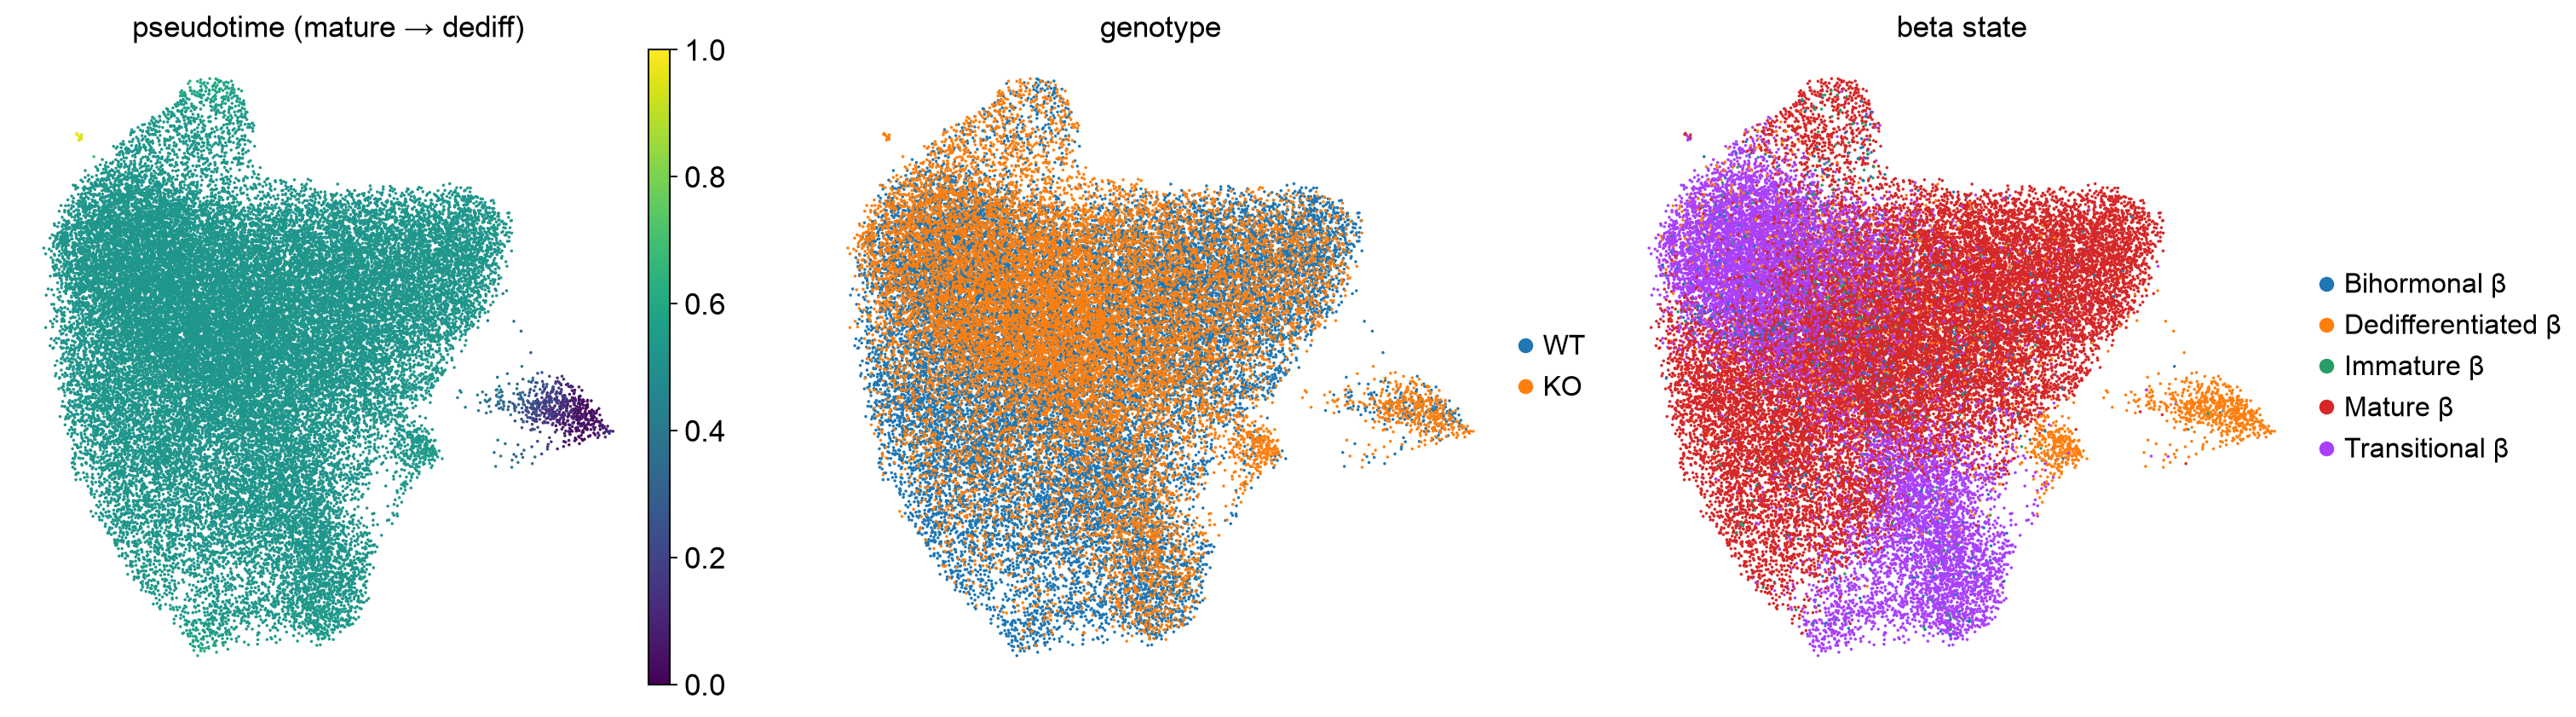

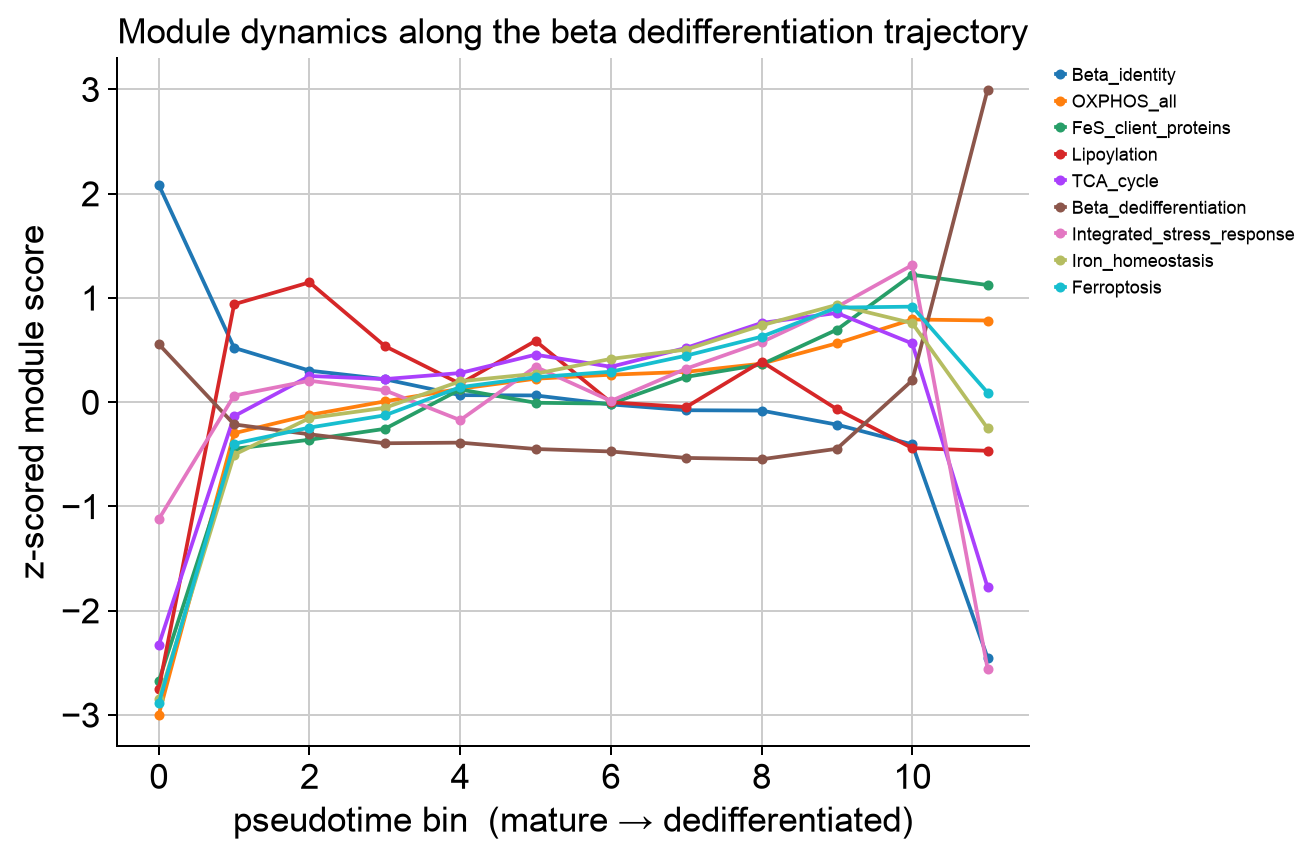

In [38]:
import scanpy as sc, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import sys; from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "resources"))
from bola3_gene_sets import GENE_SETS, filter_sets

STATE_LABELS = {"0":"Mature β","1":"Mature β","4":"Mature β","5":"Mature β","6":"Immature β",
    "2":"Dedifferentiated β","9":"Dedifferentiated β","3":"Transitional β","7":"Transitional β","na":"Bihormonal β"}

beta = adata[(adata.obs.cell_type.isin(["beta","beta_bihormonal"]))
             & (adata.obs.recomb_tier.isin(["WT","high_KO"]))
             & (~adata.obs.beta_cluster.astype(str).isin(["8","10"]))].copy()
beta.X = beta.layers["lognorm"].copy()
beta.obs["beta_state"] = pd.Categorical(beta.obs.beta_cluster.astype(str).map(lambda c: STATE_LABELS.get(c,c)))
print(f"{beta.n_obs} beta cells (WT + high_KO)")

sc.pp.neighbors(beta, use_rep="X_pca_harmony", n_neighbors=30, random_state=0)
sc.tl.diffmap(beta); sc.tl.umap(beta, random_state=0)

FS = ["Beta_identity","OXPHOS_all","FeS_client_proteins","Lipoylation","TCA_cycle",
      "Beta_dedifferentiation","Integrated_stress_response","Iron_homeostasis","Ferroptosis"]
sets = filter_sets({k: GENE_SETS[k] for k in FS if k in GENE_SETS}, beta.var_names, min_genes=4, verbose=False)
for name, genes in sets.items():
    sc.tl.score_genes(beta, genes, score_name=f"m_{name}", random_state=0)

wt = beta.obs.index[beta.obs.genotype == "WT"]
beta.uns["iroot"] = int(beta.obs_names.get_loc(beta.obs.loc[wt, "m_Beta_identity"].idxmax()))
sc.tl.dpt(beta)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.9))
sc.pl.umap(beta, color="dpt_pseudotime", ax=axes[0], show=False, cmap="viridis", size=8, frameon=False, title="pseudotime (mature → dediff)")
sc.pl.umap(beta, color="genotype", ax=axes[1], show=False, palette={"WT":"#1f77b4","KO":"#ff7f0e"}, size=8, frameon=False, title="genotype")
sc.pl.umap(beta, color="beta_state", ax=axes[2], show=False, size=8, frameon=False, title="beta state")
fig.tight_layout(); fig.savefig(cfg.FIG_DIR/"06_beta_pseudotime_umap.png", dpi=300, bbox_inches="tight"); plt.show()

mods = [f"m_{k}" for k in FS if f"m_{k}" in beta.obs]
beta.obs["pt_bin"] = pd.qcut(beta.obs.dpt_pseudotime, 12, labels=False, duplicates="drop")
zp = beta.obs.groupby("pt_bin")[mods].mean()
zp = (zp - zp.mean()) / zp.std()
fig, ax = plt.subplots(figsize=(7.6, 5))
for m in mods:
    ax.plot(zp.index, zp[m], marker="o", ms=3, label=m.replace("m_", ""))
ax.set_xlabel("pseudotime bin  (mature → dedifferentiated)"); ax.set_ylabel("z-scored module score")
ax.legend(fontsize=7, frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_title("Module dynamics along the beta dedifferentiation trajectory")
sns.despine(); fig.tight_layout(); fig.savefig(cfg.FIG_DIR/"06_beta_pseudotime_modules.png", dpi=300, bbox_inches="tight"); plt.show()

38390 beta cells (WT + high_KO)


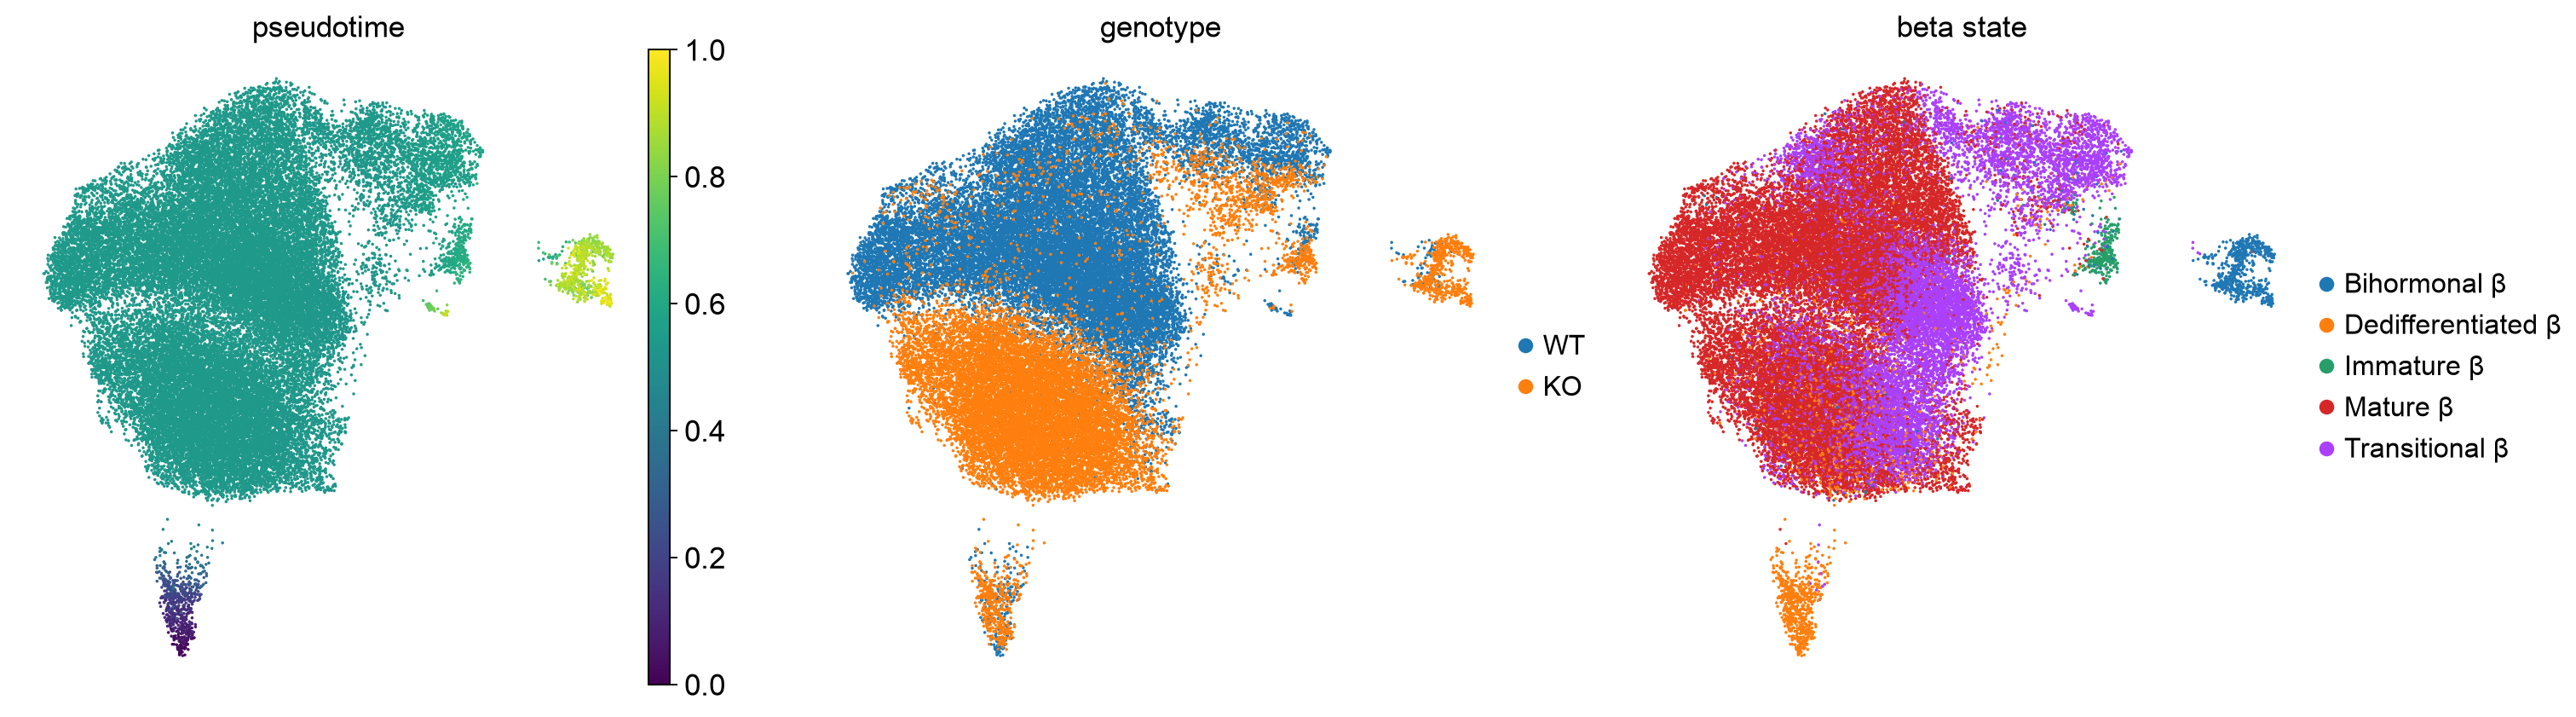

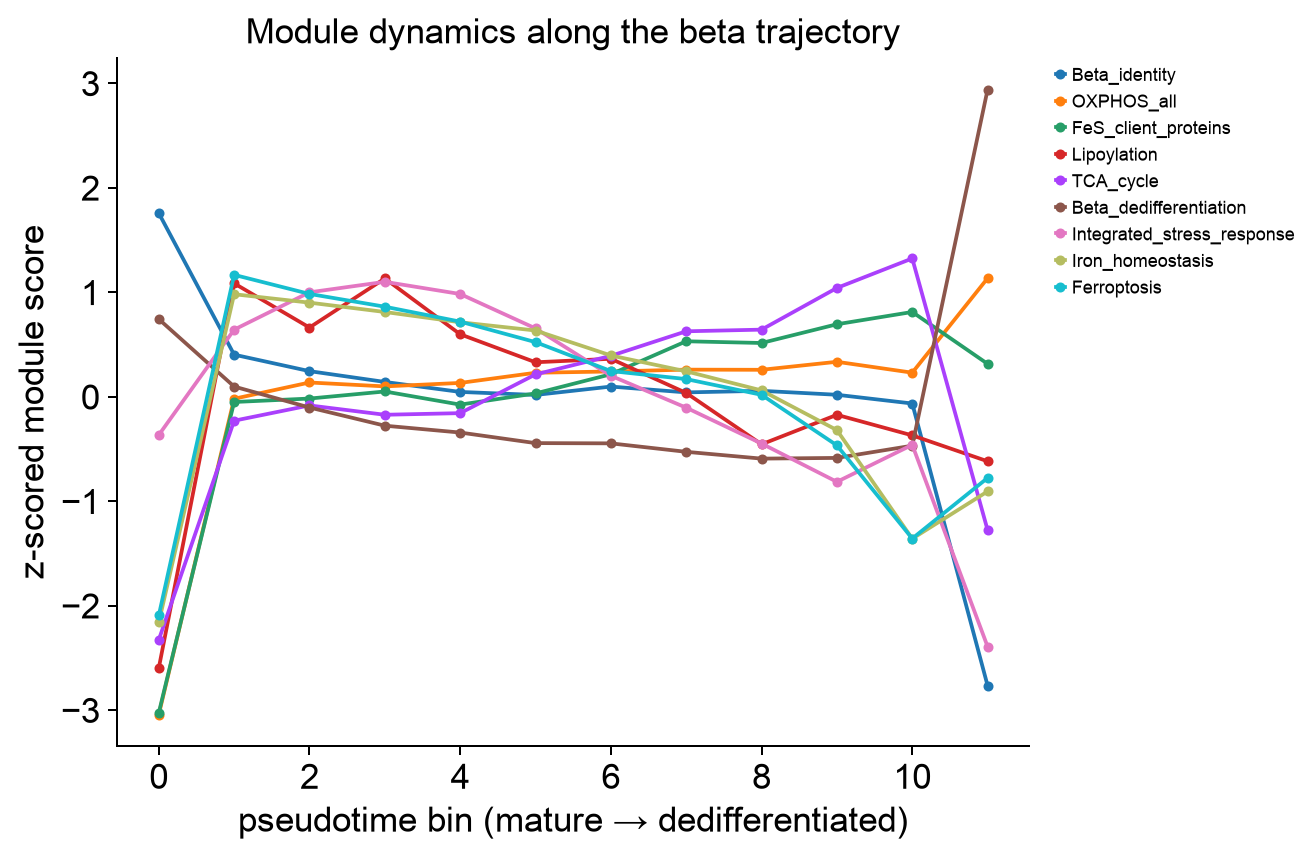

In [39]:
import scanpy as sc, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import sys; from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "resources"))
from bola3_gene_sets import GENE_SETS, filter_sets

STATE_LABELS = {"0":"Mature β","1":"Mature β","4":"Mature β","5":"Mature β","6":"Immature β",
    "2":"Dedifferentiated β","9":"Dedifferentiated β","3":"Transitional β","7":"Transitional β","na":"Bihormonal β"}

beta = adata[(adata.obs.cell_type.isin(["beta","beta_bihormonal"]))
             & (adata.obs.recomb_tier.isin(["WT","high_KO"]))
             & (~adata.obs.beta_cluster.astype(str).isin(["8","10"]))].copy()
beta.X = beta.layers["lognorm"].copy()
beta.obs["beta_state"] = pd.Categorical(beta.obs.beta_cluster.astype(str).map(lambda c: STATE_LABELS.get(c,c)))
print(f"{beta.n_obs} beta cells (WT + high_KO)")

# --- BETA-SPECIFIC embedding (resolves the within-beta continuum) ---
sc.pp.highly_variable_genes(beta, n_top_genes=2000)
sc.pp.pca(beta, n_comps=30)
sc.pp.neighbors(beta, use_rep="X_pca", n_neighbors=30, random_state=0)
sc.tl.diffmap(beta); sc.tl.umap(beta, random_state=0)

FS = ["Beta_identity","OXPHOS_all","FeS_client_proteins","Lipoylation","TCA_cycle",
      "Beta_dedifferentiation","Integrated_stress_response","Iron_homeostasis","Ferroptosis"]
sets = filter_sets({k: GENE_SETS[k] for k in FS if k in GENE_SETS}, beta.var_names, min_genes=4, verbose=False)
for name, genes in sets.items():
    sc.tl.score_genes(beta, genes, score_name=f"m_{name}", random_state=0)

wt = beta.obs.index[beta.obs.genotype == "WT"]
beta.uns["iroot"] = int(beta.obs_names.get_loc(beta.obs.loc[wt, "m_Beta_identity"].idxmax()))
sc.tl.dpt(beta)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.9))
sc.pl.umap(beta, color="dpt_pseudotime", ax=axes[0], show=False, cmap="viridis", size=8, frameon=False, title="pseudotime")
sc.pl.umap(beta, color="genotype", ax=axes[1], show=False, palette={"WT":"#1f77b4","KO":"#ff7f0e"}, size=8, frameon=False, title="genotype")
sc.pl.umap(beta, color="beta_state", ax=axes[2], show=False, size=8, frameon=False, title="beta state")
fig.tight_layout(); fig.savefig(cfg.FIG_DIR/"06_beta_pseudotime_umap.png", dpi=300, bbox_inches="tight"); plt.show()

mods = [f"m_{k}" for k in FS if f"m_{k}" in beta.obs]
beta.obs["pt_bin"] = pd.qcut(beta.obs.dpt_pseudotime, 12, labels=False, duplicates="drop")
zp = beta.obs.groupby("pt_bin")[mods].mean(); zp = (zp - zp.mean()) / zp.std()
fig, ax = plt.subplots(figsize=(7.6, 5))
for m in mods: ax.plot(zp.index, zp[m], marker="o", ms=3, label=m.replace("m_", ""))
ax.set_xlabel("pseudotime bin (mature → dedifferentiated)"); ax.set_ylabel("z-scored module score")
ax.legend(fontsize=7, frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(False)
ax.set_title("Module dynamics along the beta trajectory"); sns.despine(); fig.tight_layout()
fig.savefig(cfg.FIG_DIR/"06_beta_pseudotime_modules.png", dpi=300, bbox_inches="tight"); plt.show()

---
## Reading the whole analysis

Assemble the answer in this order, because it is the order in which the claims
depend on each other:

1. **Is Bola3 gone?** (notebook 05, section 5.2) Nothing else counts otherwise.
2. **Is the direct biochemistry disrupted?** Lipoylation and complex II
   down — this is the mechanistic anchor.
3. **Is there a stress response?** ISR up, Atf4 activity up.
4. **Do beta cells lose identity?** Beta identity down, dedifferentiation and
   the disallowed genes up.
5. **Does composition change?** (notebook 04) Usually the last thing to move —
   cells become dysfunctional well before they disappear.

A negative at step 2 with positives further down is the most important pattern
to watch for: it means the downstream changes are not attributable to the
mechanism you assumed, and the paper needs a different explanation.

### Optional extensions, once the above is settled

- **Reference mapping.** Project onto a published mouse islet atlas (Baron
  2016, Tabula Muris Senis pancreas) with `scArches`/scANVI, following
  `Fig2_map_to_primary/primary_mapping/02_train_scanvi_and_map.py`. Independent
  confirmation of your annotation, and it places the KO state relative to
  published diabetic models.
- **Trajectory.** If beta cells form a mature-to-dedifferentiated continuum,
  diffusion pseudotime along it is more informative than discrete substates.
  HNOCA's moscot approach needs real time points, which you do not have, so use
  `sc.tl.dpt` with a mature beta cell as root.
- **Cell-cell communication.** If macrophages changed, `liana` will test
  whether stressed beta cells are signalling to them.
- **Metabolic flux.** `compass` or `scFEA` estimate flux from expression. Worth
  it given the mitochondrial hypothesis, though both are slow on CPU.